# Section 1: Data acquisition and exploration

ML4N - Group Project 4

In this notebook we run step by step the preprocessing in `src/data.py` and then we do the EDA. The functions are
imported from `src/data.py` (and `src/eda.py` for the EDA) instead of being copied here, so the notebook and
`python -m src.data` produce the same files in `data/processed/`:

- `dataset_10apps.csv`: raw flows of the 10 apps
- `class_distribution_10apps.csv`: number and % of flows per app
- `model_ready.csv`: feature matrix X + `label` column
- `groups.csv`: `Flow.ID` of each row (needed for the split)

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# move to the project root, otherwise the relative paths in src/data.py don't work
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
PLOTS_DIR = Path("results/plots")  # plots for the report
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

from scipy.stats import ks_2samp
from sklearn.decomposition import PCA
from sklearn.metrics import mutual_info_score
from sklearn.preprocessing import MinMaxScaler, StandardScaler

from src.data import (
    APPS, SERVICE_PORTS, REDUNDANT_FEATURES, load_dataset, filter_10_apps, get_class_distribution,
    make_ovr_target, prepare_dataset_for_model, split_by_flow, get_continuous_columns, scale_features,
)
from src.eda import (
    feature_label, summary_statistics, univariate_auc, mutual_information, correlation_pairs,
    feature_clusters, select_non_redundant, exact_vs_range_mi,
)

## 1.1 Data acquisition

The dataset is *IP Network Traffic Flows Labeled with 75 Apps* from Kaggle [1]: about 3.58M flows of 78 apps (~1.7 GB).
Each row is a bidirectional flow identified by the 5-tuple (source/destination IP and port, protocol), with a timestamp
and ~80 statistics computed by CICFlowMeter [2] (packet counts and lengths, inter-arrival times, TCP flags, window
sizes...). The app is in the `ProtocolName` column.

`filter_10_apps` keeps only the 10 apps in `APPS`. Since reading the raw csv is slow, we save the filtered file the
first time and then we just reload it.

Note on the labels: they are not manual. `L7Protocol` contains the protocol IDs of nDPI (e.g. 119 = Facebook,
124 = YouTube, see the output below), so `ProtocolName` comes from a DPI tool that recognizes the app from the content
of the packets (like the server name in TLS/HTTP) and from lists of known server IPs. So some labels could be wrong.
Also, AMAZON and CLOUDFLARE are cloud/CDN providers more than real applications.

In the same cell we also check the data quality: there are no NaN or infinite values (in CICFlowMeter data they usually
come from rates like `Flow.Bytes.s` when the duration is 0), and the only negative values are the `-1` in
`Init_Win_bytes_*`, which we handle in Section 1.2.

In [2]:
processed_path = Path("data/processed/dataset_10apps.csv")
if not processed_path.exists():
    df_raw = pd.read_csv("data/raw/dataset.csv", low_memory=False)  # low_memory=False, otherwise pandas gives a dtype warning
    df_10apps = filter_10_apps(df_raw)
    df_10apps.to_csv(processed_path, index=False)
    dist = get_class_distribution(df_10apps)
    dist.to_csv("data/processed/class_distribution_10apps.csv")
    del df_raw, df_10apps
else:
    print(f"{processed_path} already exists, loading it")

df = load_dataset(processed_path)
print(f"Shape: {df.shape}")
numeric = df.select_dtypes("number")
print("Missing values:", df.isna().sum().sum())
print("Infinite values:", np.isinf(numeric).sum().sum())
print("Columns with negative values:", numeric.columns[(numeric < 0).any()].tolist())
print("L7Protocol code of each app:", df.groupby("ProtocolName")["L7Protocol"].first().to_dict())
df.head()

data/processed/dataset_10apps.csv already exists, loading it


Shape: (504885, 87)
Missing values: 0
Infinite values: 0
Columns with negative values: ['Init_Win_bytes_forward', 'Init_Win_bytes_backward']
L7Protocol code of each app: {'AMAZON': 178, 'CLOUDFLARE': 220, 'DROPBOX': 121, 'FACEBOOK': 119, 'GMAIL': 122, 'MICROSOFT': 212, 'SKYPE': 125, 'TWITTER': 120, 'WINDOWS_UPDATE': 147, 'YOUTUBE': 124}


,Flow.ID,Source.IP,Source.Port,Destination.IP,Destination.Port,Protocol,Timestamp,Flow.Duration,Total.Fwd.Packets,Total.Backward.Packets,...,Active.Std,Active.Max,Active.Min,Idle.Mean,Idle.Std,Idle.Max,Idle.Min,Label,L7Protocol,ProtocolName
0,192.168.72.43-10.200.7.7-55980-3128-6,192.168.72.43,55980,10.200.7.7,3128,6,26/04/201711:11:17,247289,15,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,124,YOUTUBE
1,179.1.4.251-10.200.7.217-443-37557-6,10.200.7.217,37557,179.1.4.251,443,6,26/04/201711:11:17,243047,21,17,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,124,YOUTUBE
2,179.1.4.251-10.200.7.217-443-37557-6,10.200.7.217,37557,179.1.4.251,443,6,26/04/201711:11:17,10022,1,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,124,YOUTUBE
3,192.168.42.31-10.200.7.5-52680-3128-6,192.168.42.31,52680,10.200.7.5,3128,6,26/04/201711:11:18,405528,7,33,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,124,YOUTUBE
4,216.58.202.225-10.200.7.195-443-44858-6,10.200.7.195,44858,216.58.202.225,443,6,26/04/201711:11:18,346773,8,3,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,124,YOUTUBE


### Class distribution

The classes are very unbalanced: YOUTUBE alone is about 1/3 of the flows, while CLOUDFLARE is less than 3%.

In [3]:
dist = get_class_distribution(df)
dist

,count,percentage_%
ProtocolName,,
YOUTUBE,170781,33.83
AMAZON,86875,17.21
MICROSOFT,54710,10.84
GMAIL,40260,7.97
WINDOWS_UPDATE,34471,6.83
SKYPE,30657,6.07
FACEBOOK,29033,5.75
DROPBOX,25102,4.97
TWITTER,18259,3.62


## 1.2 Data preprocessing

### One-vs-rest labels

For each app we train a binary detector: class 1 = that app, class 0 = the other 9 apps. `make_ovr_target` builds the
0/1 label from `ProtocolName`.

The share of positives is just the mean of the 0/1 vector, so it's the same as the percentages above. Class 1 is
always the minority class, we have to keep this in mind when we choose the metrics.

In [4]:
ovr_share = pd.Series(
    {app: make_ovr_target(df["ProtocolName"], app).mean() * 100 for app in APPS},
    name="positive_share_%",
).round(2)
ovr_share

YOUTUBE           33.83
AMAZON            17.21
GMAIL              7.97
WINDOWS_UPDATE     6.83
MICROSOFT         10.84
FACEBOOK           5.75
DROPBOX            4.97
SKYPE              6.07
TWITTER            3.62
CLOUDFLARE         2.92
Name: positive_share_%, dtype: float64

### Feature cleaning and encoding

`prepare_dataset_for_model` converts the filtered dataset into a numeric feature matrix. The steps are:

0. **Duplicate rows**: 36 rows are identical in all the 87 columns (also `Flow.ID` and `Timestamp`), so they are the
   same flow exported twice and we remove them. Other ~22.5k rows have the same feature values but are different flows
   (different IPs, ports, times). They are almost all very small flows with 2-3 packets, so it's normal that they look
   the same, and we keep them since they are real traffic. About 11k of them (2.2% of the flows) have the same features
   as a flow of a *different* app, so on these flows some error is unavoidable.
1. **Groups**: we save `Flow.ID` before dropping it. The same ID appears in more rows (278,380 distinct IDs for 504,849
   rows), so in the split we keep all the rows of a flow on the same side to avoid leakage.
2. **Target**: `ProtocolName` becomes `y`. We also drop `L7Protocol`, because it's just the numeric code of
   `ProtocolName` and it would leak the label.
3. **Identifiers**: `Source.IP`, `Destination.IP` and `Timestamp` describe the specific capture and not the app, the
   model would just memorize them (and `Destination.IP` would leak the label, since nDPI also uses server addresses).
   We drop `Source.Port` too: it's categorical like `Destination.Port`, but with 36k values one-hot encoding is not
   possible, and as a number it doesn't make sense (51234 and 51235 are not "similar"). Below we check that we don't
   lose much.
4. **Constant columns**: columns with only one value give no information (e.g. the `*Bulk*` features and some flag
   counts are always 0, `Label` is always `BENIGN`).
5. **Duplicate columns**: columns equal to a previous one, like `Fwd.Header.Length.1` or the `Subflow.*` columns that
   repeat the `Total.*` ones. We also drop `SYN.Flag.Count` because it's identical to `Fwd.PSH.Flags` in every row. Two
   different flags can't be equal in all the flows, so CICFlowMeter probably computes one of them wrong, and we are not
   sure if `Fwd.PSH.Flags` is really PSH or SYN.
6. **`-1` in `Init_Win_bytes_*`**: CICFlowMeter writes `-1` when it can't see the initial TCP window, so it's a missing
   value and not a real window size.
   - `Init_Win_bytes_forward` is `-1` exactly for the 365 UDP flows (no TCP window). This is already in `Protocol_17`,
     so we just replace `-1` with 0.
   - `Init_Win_bytes_backward` is `-1` in ~50k flows (~10%), almost always when the server never sent a packet. Since 0
     is also a valid window, we replace `-1` with 0 and we add the flag `Init_Win_bytes_backward_missing`.

   We didn't drop these rows because it would remove 10% of the data, and the flag is actually useful (it's 1 in 41% of
   the FACEBOOK flows). Imputing with the median would mean inventing a window for flows where the server never answered.
7. **One-hot encoding**:
   - `Protocol` (6 = TCP, 17 = UDP) is categorical. With 2 values one column is enough: `Protocol_17` = 1 for UDP and 0
     for TCP.
   - `Destination.Port` is categorical too. Ports 3128, 443 and 80 (`SERVICE_PORTS`) cover ~93.8% of the flows, all the
     others go in `Other`, otherwise we would get thousands of almost empty columns. We keep all 4 columns even if they
     sum to 1: this is a problem only for linear models without regularization, not for trees and MLP.
     `Destination.Port_Other` is also interesting because it marks the inverted flows (see below).

In [5]:
X, y, groups = prepare_dataset_for_model(df)

print(f"X shape: {X.shape}")
print(f"Number of distinct groups (for Flow.ID): {groups.nunique():,}")
one_hot_cols = [c for c in X.columns if c.startswith("Protocol_") or c.startswith("Destination.Port_")]
print(f"One-hot columns ({len(one_hot_cols)}): {one_hot_cols}")
print(f"Duplicate rows removed: {len(df) - len(X)}")
print(f"-1 left in Init_Win_bytes_*: {(X[['Init_Win_bytes_forward', 'Init_Win_bytes_backward']] == -1).sum().sum()}")
print(f"Init_Win_bytes_backward_missing = 1: {X['Init_Win_bytes_backward_missing'].mean() * 100:.2f}% of the flows")

# rows with the same features but a different app (no model can get all of them right)
same_features = pd.util.hash_pandas_object(X, index=False)
conflicting = y.groupby(same_features).transform("nunique") > 1
print(f"Rows whose features also appear with another app: {conflicting.sum():,} ({conflicting.mean() * 100:.1f}%)")

X shape: (504849, 67)
Number of distinct groups (for Flow.ID): 278,380
One-hot columns (5): ['Protocol_17', 'Destination.Port_3128', 'Destination.Port_443', 'Destination.Port_80', 'Destination.Port_Other']
Duplicate rows removed: 36
-1 left in Init_Win_bytes_*: 0
Init_Win_bytes_backward_missing = 1: 9.90% of the flows


Rows whose features also appear with another app: 11,066 (2.2%)


List of the columns of the filtered dataset that are not in X (`Protocol` and `Destination.Port` are not counted since
they are replaced by the one-hot columns). Useful for the report.

In [6]:
dropped = [c for c in df.columns if c not in X.columns and c not in ("Protocol", "Destination.Port")]
print(f"Dropped columns ({len(dropped)}): {dropped}")

Dropped columns (24): ['Flow.ID', 'Source.IP', 'Source.Port', 'Destination.IP', 'Timestamp', 'Bwd.PSH.Flags', 'Fwd.URG.Flags', 'Bwd.URG.Flags', 'SYN.Flag.Count', 'CWE.Flag.Count', 'Fwd.Header.Length.1', 'Fwd.Avg.Bytes.Bulk', 'Fwd.Avg.Packets.Bulk', 'Fwd.Avg.Bulk.Rate', 'Bwd.Avg.Bytes.Bulk', 'Bwd.Avg.Packets.Bulk', 'Bwd.Avg.Bulk.Rate', 'Subflow.Fwd.Packets', 'Subflow.Fwd.Bytes', 'Subflow.Bwd.Packets', 'Subflow.Bwd.Bytes', 'Label', 'L7Protocol', 'ProtocolName']


#### Why we drop `Source.Port`

As said above, `Source.Port` can't be used as it is (36k categories, and as a number it has no meaning). But it's not
an identifier like the IPs or the timestamp, so we wanted to check what we lose by dropping it.

Usually it's the ephemeral port of the client, but in some flows the first packet seen by CICFlowMeter comes from the
server, so source and destination are swapped: the service port ends up in `Source.Port` and the client port in
`Destination.Port` (we call them *inverted* flows). In the next cell we check:
- how many flows are inverted and if `Destination.Port_Other` already identifies them;
- how much information the service port of the inverted flows would add (mutual information with the app);
- if the client port in the normal flows is really random (every OS uses its own range of ephemeral ports).

In [7]:
sport, dport, app = df["Source.Port"], df["Destination.Port"], df["ProtocolName"]
dport_service, sport_service = dport.isin(SERVICE_PORTS), sport.isin(SERVICE_PORTS)
inverted = ~dport_service & sport_service  # service port in Source.Port, client's port in Destination.Port
print(f"Distinct Source.Port values: {sport.nunique():,}")
print(f"Inverted flows: {inverted.mean() * 100:.1f}% of all flows, {inverted[app == 'DROPBOX'].mean() * 100:.1f}% of DROPBOX")
print(f"Flows in Destination.Port_Other that are inverted: {inverted[~dport_service].mean() * 100:.1f}%")
print("Service port of the inverted flows [%]:", (sport[inverted].value_counts(normalize=True) * 100).round(1).to_dict())

# our encoding vs service port taken from both sides + inverted flag
current = dport.where(dport_service, "Other").astype(str)
service = dport.where(dport_service, sport.where(sport_service, "Other")).astype(str) + "_" + inverted.astype(str)
print(f"MI with the app (nats): Destination.Port encoding = {mutual_info_score(app, current):.3f}, "
      f"service port + inverted flag = {mutual_info_score(app, service):.3f}")

# ranges of the client port (only non-inverted flows)
ranges = pd.cut(sport[dport_service], [0, 1023, 5000, 32767, 49151, 65535],
                labels=["0-1023", "1024-5000", "5001-32767", "32768-49151", "49152-65535"])
print(f"MI with the app (nats), client port range = {mutual_info_score(app[dport_service], ranges.astype(str)):.3f}")
(pd.crosstab(app[dport_service], ranges, normalize="index") * 100).loc[APPS].round(1)

Distinct Source.Port values: 36,253
Inverted flows: 6.1% of all flows, 64.0% of DROPBOX
Flows in Destination.Port_Other that are inverted: 97.3%
Service port of the inverted flows [%]: {443: 77.0, 80: 11.9, 3128: 11.1}


MI with the app (nats): Destination.Port encoding = 0.374, service port + inverted flag = 0.394


MI with the app (nats), client port range = 0.039


Source.Port,1024-5000,5001-32767,32768-49151,49152-65535
ProtocolName,,,,
YOUTUBE,4.0,0.4,29.8,65.8
AMAZON,0.7,0.1,56.2,43.0
GMAIL,2.8,0.4,29.2,67.6
WINDOWS_UPDATE,0.0,0.0,11.0,89.0
MICROSOFT,1.1,0.1,29.8,69.0
FACEBOOK,5.2,0.4,32.8,61.5
DROPBOX,1.8,0.3,32.5,65.4
SKYPE,3.1,0.0,34.6,62.3
TWITTER,4.8,1.5,31.5,62.1


What we found:
- The raw value can't be used: 36k values, mostly random, that a tree could just memorize.
- We don't really lose the inverted flows. They are 6.1% of the flows (64% of DROPBOX), and 97.3% of the flows in
  `Destination.Port_Other` are inverted, so that column already works as an "inverted" flag (it's also the best single
  feature for DROPBOX, see 1.3). The only thing we lose is which service port they use (443 in 77% of them, 80 and 3128
  about 11-12% each). If we took the service port from both sides and added an inverted flag, the MI of the port
  encoding would go from 0.374 to 0.394 nats, so only +5%.
- The client port is not completely random. 32768-49151 is in the default range of Linux/Android (32768-60999) but not
  in the one of Windows/macOS (49152-65535). WINDOWS_UPDATE, which is mostly Windows clients, has only 11% of its flows
  in that range, the other apps 29-56%. So the client port partially tells the OS of the client (0.039 nats, ~1/10 of
  the destination port). But this is about the device and not the app, and the client can choose any port, so for an
  attacker it would be very easy to change (Section 3).

So dropping `Source.Port` is fine: the useful part is already in `Destination.Port_Other` and the rest is something the
attacker controls completely. If we need it in Section 2, we can still recover the service port of the inverted flows
like we did above.

We save X (with the `label` column) and the groups, so in the next notebooks we can load them directly with `load_model_ready` (it also
drops the 3 redundant features found in the EDA, see the end of 1.3). The label is kept as the app name, the 0/1 target is built later with `make_ovr_target` for the app we are studying.

The files are written only if they don't exist: if `prepare_dataset_for_model` is changed, delete them or run
`python -m src.data`.

In [8]:
model_ready_path = Path("data/processed/model_ready.csv")
groups_path = Path("data/processed/groups.csv")
if not model_ready_path.exists() or not groups_path.exists():
    X_to_save = X.copy()
    X_to_save["label"] = y
    X_to_save.to_csv(model_ready_path, index=False)
    pd.DataFrame({"Flow.ID": groups}).to_csv(groups_path, index=False)
    print("model_ready.csv and groups.csv saved successfully!")
else:
    print("model_ready.csv and groups.csv already exist, skipping")

model_ready.csv and groups.csv already exist, skipping


### Train/test split by Flow.ID

We use the whole filtered dataset without sampling: ~505k rows x 67 features is a few hundred MB, so it fits in memory.
If some model in Section 2 is too slow on 400k flows (e.g. SVM with a kernel), we will tune it on a stratified sample
of the training set.

`split_by_flow` uses `StratifiedGroupKFold` from scikit-learn [3] with 5 folds, and we take the first fold as test set
(80/20):
- grouped by `Flow.ID`: the same flow can appear in up to 107 rows, and if they end up both in train and test the model
  is tested on flows it has already seen, so the results would be too optimistic;
- stratified on the app (the 10 classes, not a single binary label), so every app has about the same % in train and
  test and we can use the same split for all the 10 detectors.

The test set is used only for the final evaluation, the cross-validation in Section 2 is done on the training set.

One limitation: the split is random over the whole capture period, so train and test flows come from the same days,
hosts and servers. The test score tells how well the detectors work on this network in this period, not what happens
if something changes over time (e.g. a server changing its TCP configuration). Splitting by day would be a harder test.

In [9]:
X_train, X_test, y_train, y_test, groups_train, groups_test = split_by_flow(X, y, groups, test_size=0.2, seed=42)

print(f"Train: {X_train.shape}  Test: {X_test.shape}  ({len(X_test) / len(X) * 100:.1f}% test)")
print(f"Flow.ID in both train and test: {len(set(groups_train) & set(groups_test))}")

pd.DataFrame({
    "train_%": (y_train.value_counts(normalize=True) * 100).round(2),
    "test_%": (y_test.value_counts(normalize=True) * 100).round(2),
})

Train: (403758, 67)  Test: (101091, 67)  (20.0% test)
Flow.ID in both train and test: 0


,train_%,test_%
ProtocolName,,
YOUTUBE,33.80,33.93
AMAZON,17.24,17.09
MICROSOFT,10.80,10.97
GMAIL,7.99,7.89
WINDOWS_UPDATE,6.84,6.78
SKYPE,6.04,6.21
FACEBOOK,5.75,5.72
DROPBOX,4.98,4.95
TWITTER,3.64,3.53


### Normalization: log1p + Min-Max in [0, 1]

Most features (bytes, packets, rates, durations, IATs) are non-negative with very long right tails. For example
`Flow.Bytes.s` has a median around 800 but a max of 3.8e9. With only Min-Max the max sets the scale, so almost all the
values end up close to 0 (see the next cell).

So `scale_features` does two steps:
1. `log1p`, i.e. $\log(1 + x)$, only on the continuous features (one-hot columns and flags are already 0/1). 0 stays 0,
   the order is preserved and big values get compressed (10 -> 2.4, 1000 -> 6.9, 1e9 -> 20.7). It's the log
   transformation we saw in class for heavy-tailed quantities like packet sizes and delays.
2. Min-Max in $[0, 1]$, $x' = (x - x_{min}) / (x_{max} - x_{min})$, fitted only on the training set. Test values outside
   the training range are clipped to [0, 1].

Why it matters for the next sections:
- MLP: inputs that are almost always ~0 are hard to learn from, with log1p they are spread over [0, 1].
- Adversarial attacks: $\varepsilon$ is measured in this space. With only Min-Max, a change of 0.05 on `Flow.Bytes.s`
  means +190 million bytes/s, so even a "small" $\varepsilon$ would allow crazy changes. After log1p a shift $\delta$
  multiplies $1 + x$ by $e^{\delta r}$ ($r$ = range of $\log(1 + x)$ on the training set), so the change is relative to
  the original value. It still depends on the feature (see the output below): for $\delta = 0.05$ it's between x1.4 and
  x3 (`Flow.Bytes.s`), except `Down.Up.Ratio` (x1.3) and `min_seg_size_forward` (x1.04, since it's only between 20 and
  44). We can go back to real units with `expm1`.
- Decision trees / Random Forest: no difference, they only look at the order of the values.

Continuous features: 54  |  binary (one-hot / flags): 13


Features with >90% of values < 0.01: Min-Max only = 22, log1p + Min-Max = 0


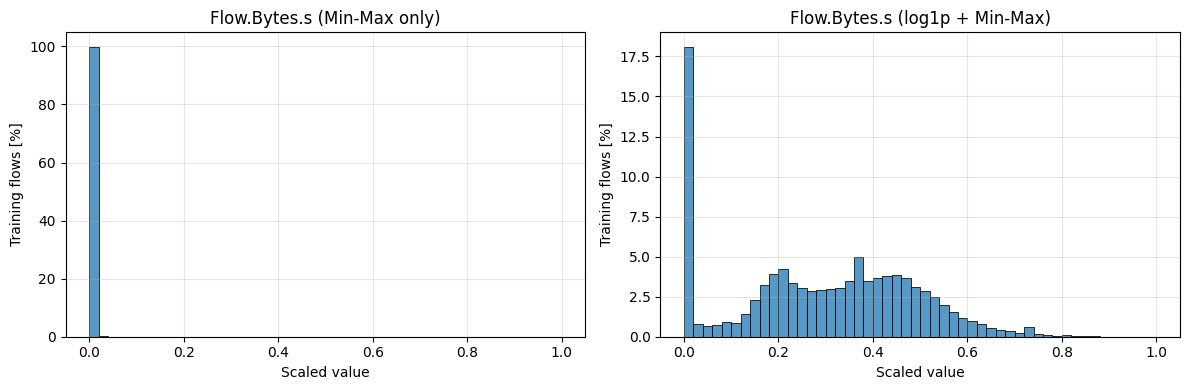

Flow.Bytes.s in the first bin [0, 0.02): Min-Max only = 99.9%, log1p + Min-Max = 18.1% (exactly 0: 16.8%)


In [10]:
cont_cols = get_continuous_columns(X_train)
print(f"Continuous features: {len(cont_cols)}  |  binary (one-hot / flags): {X_train.shape[1] - len(cont_cols)}")

# % of values < 0.01 for each feature, with and without log1p
plain = MinMaxScaler().fit_transform(X_train[cont_cols])
logged = MinMaxScaler().fit_transform(np.log1p(X_train[cont_cols]))
print(f"Features with >90% of values < 0.01: Min-Max only = {((plain < 0.01).mean(axis=0) > 0.9).sum()}, "
      f"log1p + Min-Max = {((logged < 0.01).mean(axis=0) > 0.9).sum()}")

# histogram of Flow.Bytes.s with the two scalings
bytes_idx = cont_cols.index("Flow.Bytes.s")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, values, name in zip(axes, [plain[:, bytes_idx], logged[:, bytes_idx]], ["Min-Max only", "log1p + Min-Max"]):
    sns.histplot(values, bins=50, binrange=(0, 1), stat="percent", ax=ax)
    ax.set_title(f"Flow.Bytes.s ({name})")
    ax.set_xlabel("Scaled value")
    ax.set_ylabel("Training flows [%]")
    ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "eda_scaling_histogram.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Flow.Bytes.s in the first bin [0, 0.02): Min-Max only = {(plain[:, bytes_idx] < 0.02).mean() * 100:.1f}%, "
      f"log1p + Min-Max = {(logged[:, bytes_idx] < 0.02).mean() * 100:.1f}% "
      f"(exactly 0: {(X_train['Flow.Bytes.s'] == 0).mean() * 100:.1f}%)")

With only Min-Max, 99.9% of the training flows are in the first bin, so for the model the feature is basically constant.
With log1p the values are spread over the whole interval. The peak at 0 is the 17% of flows with 0 bytes/s (no payload),
and no monotonic transformation can spread those. We didn't add the KDE because with the bound at 0 and so many zeros
it would put some density on negative values.

In [11]:
X_train_scaled, X_test_scaled, scaler = scale_features(X_train, X_test)

print(f"Train range: [{X_train_scaled.to_numpy().min():.2f}, {X_train_scaled.to_numpy().max():.2f}]")
print(f"Test range:  [{X_test_scaled.to_numpy().min():.2f}, {X_test_scaled.to_numpy().max():.2f}]")
# how much 1 + x gets multiplied if we move a feature by 0.05 in the scaled space
factor = pd.Series(np.exp(0.05 * scaler.data_range_), index=X_train_scaled.columns)[cont_cols].sort_values()
print("Shift of 0.05 -> 1 + x multiplied by:", factor.iloc[[0, 1, 2, len(factor) // 2, -1]].round(2).to_dict())
X_train_scaled.describe().T[["mean", "50%", "min", "max"]].head(10)

Train range: [0.00, 1.00]
Test range:  [0.00, 1.00]
Shift of 0.05 -> 1 + x multiplied by: {'min_seg_size_forward': 1.04, 'Down.Up.Ratio': 1.31, 'Min.Packet.Length': 1.44, 'Packet.Length.Variance': 2.35, 'Flow.Bytes.s': 3.01}


,mean,50%,min,max
Flow.Duration,0.693220,0.762224,0.0,1.0
Total.Fwd.Packets,0.145304,0.119674,0.0,1.0
Total.Backward.Packets,0.194767,0.163438,0.0,1.0
Total.Length.of.Fwd.Packets,0.293219,0.354890,0.0,1.0
Total.Length.of.Bwd.Packets,0.306773,0.340615,0.0,1.0
Fwd.Packet.Length.Max,0.446676,0.563307,0.0,1.0
Fwd.Packet.Length.Min,0.044708,0.000000,0.0,1.0
Fwd.Packet.Length.Mean,0.395588,0.474617,0.0,1.0
Fwd.Packet.Length.Std,0.413518,0.552525,0.0,1.0
Bwd.Packet.Length.Max,0.468562,0.546338,0.0,1.0


## 1.3 Exploratory data analysis

We do the EDA only on the training set (`X_train`, `y_train`), so the choices we make here (features, transformations,
attack targets) don't use any information from the test set. With ~400k flows the statistics are basically the same as
on the whole dataset anyway.

Some notes on the plots:
- we use the features before log1p and Min-Max (`X_train`, not `X_train_scaled`), so the values are in the original
  units: bytes, packets, and microseconds for durations and IATs (CICFlowMeter uses µs);
- since most features have long tails and lots of zeros, we use a `symlog` axis (linear between 0 and 1, log above), so
  the zeros are still visible together with values up to $10^8$;
- a plot with 10 colors is hard to read, so we compare the distributions side by side (one box per app), and for the
  scatter plots we use one panel per app, with the app in color and the other 9 in gray (which is the one-vs-rest view
  anyway);
- the main figures are saved in `results/plots/` for the report.

In [12]:
cont_cols = get_continuous_columns(X_train)
binary_cols = [c for c in X_train.columns if c not in cont_cols]
print(f"Training flows: {len(X_train):,}, continuous features: {len(cont_cols)}, binary features: {len(binary_cols)}")

Training flows: 403,758, continuous features: 54, binary features: 13


### Shape of the distributions

The continuous features can be grouped in a few families:
- volume: packets and bytes per direction (`Total.*`, `*.Header.Length`, `act_data_pkt_fwd`)
- packet size: min/max/mean/std of the packet lengths (`*Packet.Length*`, `*Segment.Size`, `Average.Packet.Size`)
- timing: duration, inter-arrival times (`*.IAT.*`), active/idle periods (`Active.*`, `Idle.*`) and rates (`*.s`)
- TCP header: initial windows (`Init_Win_bytes_*`), `min_seg_size_forward`, `Down.Up.Ratio`

`summary_statistics` computes for each feature: % of zeros, mean, median, 99th percentile, max, skewness, and % of
points outside the Tukey fences $[Q_1 - 1.5\,IQR,\ Q_3 + 1.5\,IQR]$, both on the raw values and after `log1p`. For
reference, for a Gaussian only ~0.7% of the points are outside the fences.

In [13]:
stats = summary_statistics(X_train[cont_cols])

print(f"Features with skewness > 2: {(stats['skewness'] > 2).sum()} / {len(stats)}")
print(f"Features with > 5% Tukey outliers: raw = {(stats['tukey_outliers_%'] > 5).sum()}, "
      f"after log1p = {(stats['tukey_outliers_log_%'] > 5).sum()}")
print(f"Features with > 50% zeros: {(stats['zeros_%'] > 50).sum()}")
nonzero_median = stats[stats["median"] > 0]
print(f"Features with mean > 2 x median: {(nonzero_median['mean'] > 2 * nonzero_median['median']).sum()} / {len(nonzero_median)} (with non-zero median)")
stats.sort_values("skewness", ascending=False).round(2)

Features with skewness > 2: 44 / 54
Features with > 5% Tukey outliers: raw = 46, after log1p = 16
Features with > 50% zeros: 14
Features with mean > 2 x median: 32 / 40 (with non-zero median)


,zeros_%,mean,median,p99,max,skewness,tukey_outliers_%,tukey_outliers_log_%
act_data_pkt_fwd,25.08,41.44,3.00,7.000000e+02,2.145870e+05,162.90,11.10,2.30
Flow.Bytes.s,16.80,594076.78,819.13,1.200000e+07,3.833000e+09,126.00,17.24,0.03
Total.Fwd.Packets,0.00,85.00,7.00,1.491430e+03,2.147210e+05,123.03,14.22,5.38
Total.Length.of.Fwd.Packets,17.62,11203.29,672.00,4.800988e+04,9.305026e+07,97.92,10.71,0.03
Fwd.Header.Length,0.00,2374.88,200.00,4.209144e+04,4.297932e+06,78.14,14.31,4.31
Min.Packet.Length,87.87,1.11,0.00,6.000000e+00,1.460000e+03,67.05,12.13,12.13
Total.Backward.Packets,9.83,128.20,6.00,2.478000e+03,1.481680e+05,54.28,15.82,5.49
Total.Length.of.Bwd.Packets,25.68,249521.24,786.00,5.745207e+06,3.178298e+08,48.93,17.53,0.00
Bwd.Header.Length,9.83,3483.84,192.00,6.825832e+04,4.601096e+06,47.30,15.02,2.54
Fwd.Packet.Length.Min,82.99,3.76,0.00,5.500000e+01,4.380000e+03,27.94,17.01,17.01


Comments:
- Almost all the features are very right-skewed (skewness up to ~160). For example `Flow.Bytes.s` has median ~800
  bytes/s, 99th percentile 1.2e7 and max 3.8e9: most flows are small, but a few "elephant" flows (long downloads and
  sessions) are several orders of magnitude bigger.
- Because of the tails the mean is much bigger than the median: more than 2x the median in 32 of the 40 features with
  non-zero median (`Flow.Bytes.s`: mean ~594k vs median ~800, `Total.Fwd.Packets`: 85 vs 7). So the median and the
  percentiles describe a typical flow much better than the mean.
- The outliers are not errors. On the raw values the Tukey rule flags 10-20% of the flows for most features (46
  features above 5%), way more than the 0.7% of a Gaussian. After `log1p` it goes to 0 for most of them, and the 16
  features still above 5% are mostly the zero-inflated ones (next point). These points are just the tail of the
  distribution (real big flows), so we keep them and let the log transform handle them instead of removing them.
- Zero-inflated features: `Active.*` and `Idle.*` are 0 in ~77% of the flows (CICFlowMeter fills them only if the flow
  has idle periods), and the min packet lengths are 0 in 83-88% of the flows (at least one packet without payload, like
  a pure ACK). For these features IQR = 0, so every non-zero value is an "outlier" even after log1p. Here the
  interesting thing is the % of non-zero values.
- We can also see some physical limits: `Flow.Duration` is never above 1.2e8 µs = 120 s (the flow timeout of
  CICFlowMeter, longer connections are split), `Init_Win_bytes_*` is never above 65535 (the TCP window field is 16 bits)
  and `min_seg_size_forward` only takes the values 20, 32, 40, 44 (TCP header size with/without options).

### Binary features per app

For the 13 binary features (one-hot port and protocol, TCP flags, missing window flag) we plot the % of flows of each
app where they are 1.

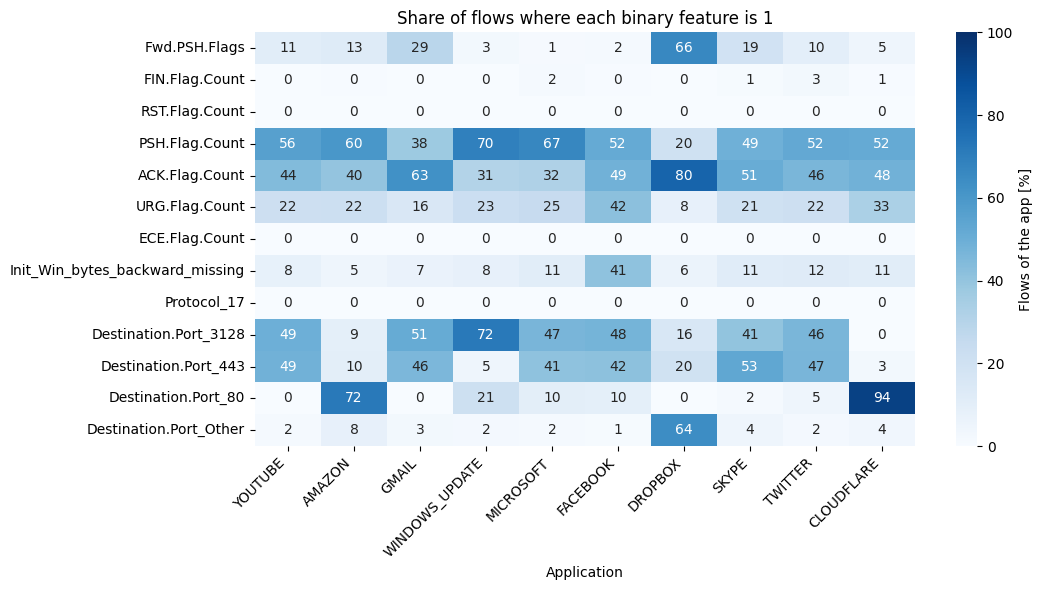

In [14]:
binary_share = X_train[binary_cols].groupby(y_train).mean().loc[APPS] * 100

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(binary_share.T, cmap="Blues", annot=True, fmt=".0f", vmin=0, vmax=100,
            cbar_kws={"label": "Flows of the app [%]"}, ax=ax)
ax.set_xlabel("Application")
ax.set_title("Share of flows where each binary feature is 1")
plt.xticks(rotation=45, ha="right")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "eda_binary_features.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
# DROPBOX: inverted flows vs normal ones
dropbox = X_train[y_train == "DROPBOX"]
is_inverted = dropbox["Destination.Port_Other"].map({0: "not inverted", 1: "inverted"})
dropbox_cols = ["Fwd.PSH.Flags", "Idle.Max", "Flow.Duration", "Init_Win_bytes_forward"]
pd.concat([
    dropbox.groupby(is_inverted).size().rename("flows"),
    dropbox.groupby(is_inverted)[dropbox_cols].median().add_prefix("median "),
    dropbox.groupby(is_inverted)["Fwd.PSH.Flags"].mean().mul(100).rename("Fwd.PSH.Flags = 1 [%]"),
], axis=1).round(1)

,flows,median Fwd.PSH.Flags,median Idle.Max,median Flow.Duration,median Init_Win_bytes_forward,Fwd.PSH.Flags = 1 [%]
Destination.Port_Other,,,,,,
inverted,12919,1.0,57252521.0,76843578.0,126.0,94.6
not inverted,7179,0.0,0.0,46843323.0,8192.0,15.1


Comments:
- For some apps the destination port alone is almost enough. 94% of the CLOUDFLARE flows and 72% of the AMAZON flows go
  to port 80 (plain HTTP, typical for CDN content), while the other apps are at most ~21%. WINDOWS_UPDATE uses the proxy
  port 3128 in 72% of the flows and almost never 443 (5%).
- DROPBOX has 64% of its flows in `Destination.Port_Other`: these are the inverted flows of Section 1.2 (`Source.Port` =
  443, client port in `Destination.Port`). From the table above they also behave differently: `Fwd.PSH.Flags` (PSH or
  SYN, see 1.2) is set in almost all of them, they are longer and have long idle periods. They look like long
  connections kept open by the client where the beginning was not captured, so the first packet seen came from the
  server. In these flows "forward" actually means server -> client, and this explains some DROPBOX patterns we see later
  (e.g. its small `Init_Win_bytes_forward`, which is actually the window of the server).
- CLOUDFLARE never goes through the proxy (~0% on port 3128) and AMAZON rarely (9%), while the other apps 16-72%.
  Through the proxy the destination address is the proxy itself, so a label based on the server IP can't be assigned.
  This suggests that nDPI recognizes these two providers mostly from their IPs. So part of the information in the port
  could come from how the labels were made and not from how the apps behave (possible shortcut learning).
- FACEBOOK has `Init_Win_bytes_backward_missing` = 1 in 41% of the flows (5-12% for the others), i.e. flows where the
  server didn't send any packet.
- Some features are almost constant: UDP (`Protocol_17`) is <= 0.2% for every app, the `RST` and `ECE` flags are ~0 and
  `FIN` <= 2.5%. They have almost no information, as the mutual information below also shows.

### Which features separate the apps?

To rank the features without training a model we use two measures:

- **Univariate ROC-AUC** (`univariate_auc`): for each app we use a single feature as the score of the one-vs-rest
  detector. AUC = probability that a random flow of the app has a bigger value than a random flow of the other apps, so
  0.5 = no separation, close to 1 (or 0) = the app has bigger (or smaller) values. We compute it from the ranks
  (Mann-Whitney U statistic), so it doesn't change with scaling or log1p. It only sees monotonic differences
  (distributions shifted up or down).
- **Mutual information** (`mutual_information`) between each feature and the 10-class label, with the k-NN estimator
  of scikit-learn [3] on a stratified sample of 100k flows. It's 0 if the feature is independent from the app and it
  can capture any kind of dependence, also non-monotonic (e.g. an app using a specific value in the middle of the
  range). The k-NN estimator is meant for continuous values and is less reliable with many ties (zero-inflated features
  or few distinct values), while for the 0/1 features the discrete formula is used. So we use these values to rank the
  features, not as exact amounts of information.

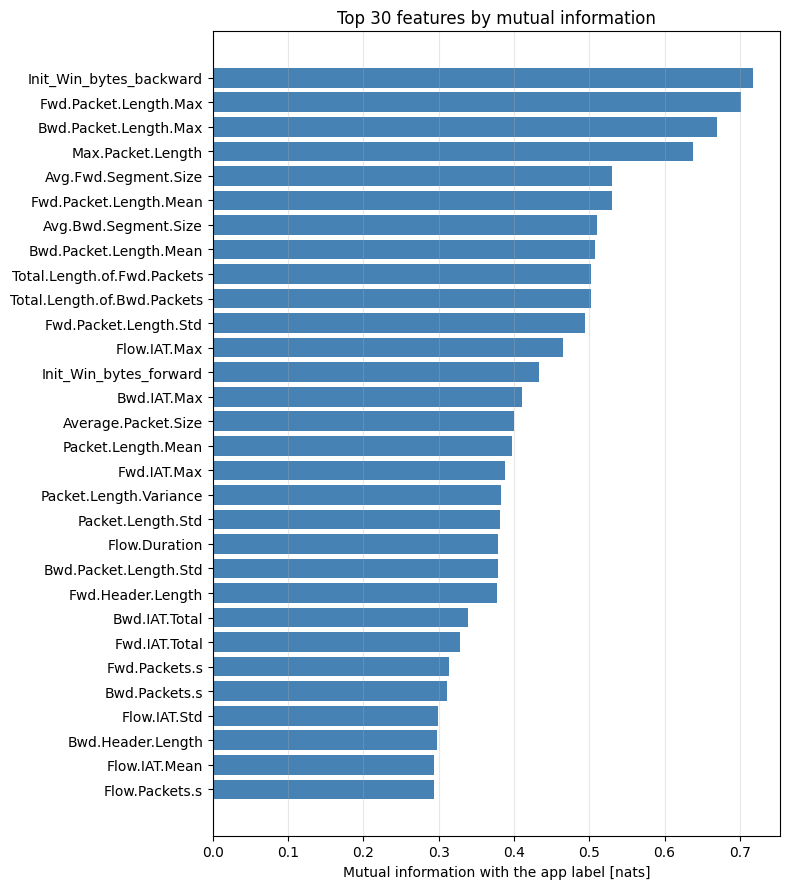

Lowest mutual information: {'Min.Packet.Length': 0.018, 'URG.Flag.Count': 0.013, 'FIN.Flag.Count': 0.003, 'Protocol_17': 0.0, 'RST.Flag.Count': 0.0, 'ECE.Flag.Count': 0.0}


In [16]:
auc = univariate_auc(X_train, y_train, APPS)
mi = mutual_information(X_train, y_train, n_samples=100_000, seed=42)

top_mi = mi.head(30)[::-1]
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(top_mi.index, top_mi.to_numpy(), color="steelblue")
ax.set_xlabel("Mutual information with the app label [nats]")
ax.set_title("Top 30 features by mutual information")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "eda_mutual_information.png", dpi=150, bbox_inches="tight")
plt.show()

print("Lowest mutual information:", mi.tail(6).round(3).to_dict())

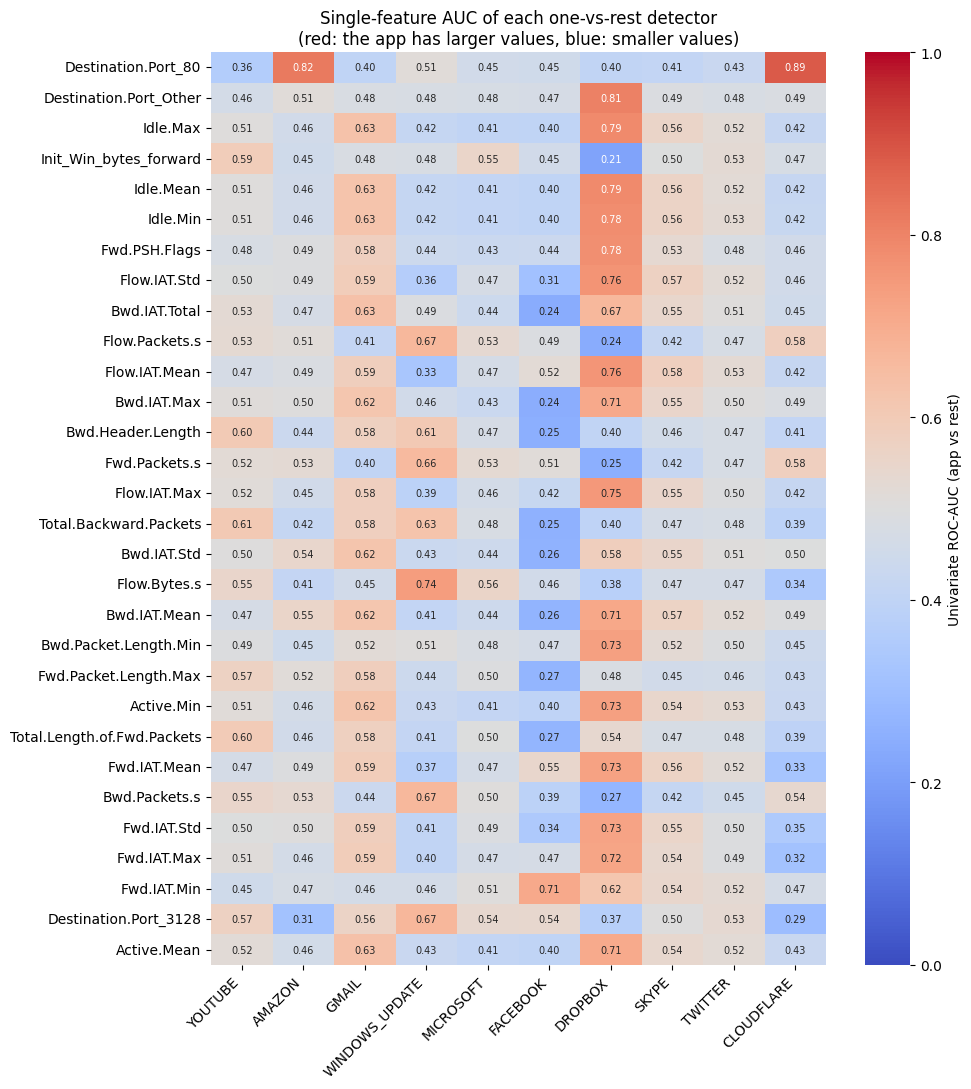

,best_feature,auc,"max(auc, 1 - auc)"
YOUTUBE,Destination.Port_80,0.36,0.64
AMAZON,Destination.Port_80,0.82,0.82
GMAIL,Active.Max,0.64,0.64
WINDOWS_UPDATE,Flow.Bytes.s,0.74,0.74
MICROSOFT,Idle.Max,0.41,0.59
FACEBOOK,Bwd.IAT.Total,0.24,0.76
DROPBOX,Destination.Port_Other,0.81,0.81
SKYPE,Destination.Port_443,0.60,0.60
TWITTER,Destination.Port_80,0.43,0.57
CLOUDFLARE,Destination.Port_80,0.89,0.89


In [17]:
# features sorted by their best separation over the 10 apps
separation = (auc - 0.5).abs()
top_auc = separation.max(axis=1).sort_values(ascending=False).head(30).index

fig, ax = plt.subplots(figsize=(10, 11))
sns.heatmap(auc.loc[top_auc], cmap="coolwarm", center=0.5, vmin=0, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, cbar_kws={"label": "Univariate ROC-AUC (app vs rest)"}, ax=ax)
ax.set_title("Single-feature AUC of each one-vs-rest detector\n(red: the app has larger values, blue: smaller values)")
plt.xticks(rotation=45, ha="right")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "eda_univariate_auc.png", dpi=150, bbox_inches="tight")
plt.show()

# best single feature for each app (AUC < 0.5 is also a separation, so we look at max(AUC, 1 - AUC))
best_feature = separation.idxmax()
best_auc = pd.Series([auc.loc[feature, app] for app, feature in best_feature.items()], index=best_feature.index)
pd.DataFrame({
    "best_feature": best_feature,
    "auc": best_auc,
    "max(auc, 1 - auc)": np.maximum(best_auc, 1 - best_auc),
}).round(2)

Comments:
- For most apps one feature is not enough. The best single feature gets AUC 0.89 for CLOUDFLARE
  (`Destination.Port_80`), ~0.8 for AMAZON and DROPBOX and ~0.75 for FACEBOOK and WINDOWS_UPDATE, but only 0.57-0.64
  (as max(AUC, 1 - AUC)) for TWITTER, MICROSOFT, SKYPE, GMAIL and YOUTUBE. For these apps the detectors will need
  combinations of features and non-linear models.
- Patterns per app (red = bigger values than the rest, blue = smaller):
  - DROPBOX: long idle periods and IATs (`Idle.*`, `Flow.IAT.*` ~0.75-0.79), `Fwd.PSH.Flags` and low packet rates
    (~0.25), so slow and long connections.
  - WINDOWS_UPDATE: high throughput (`Flow.Bytes.s` 0.74) and many big backward packets, i.e. downloads from the server.
  - FACEBOOK: few backward packets and short backward activity (`Bwd.*` ~0.24-0.27), consistent with the 41% of flows
    where the server doesn't answer.
  - AMAZON and CLOUDFLARE: port 80, and the CLOUDFLARE flows are also short (`Fwd.IAT.*` ~0.32).
- The mutual information gives a different ranking: the top features are `Init_Win_bytes_backward` and the max packet
  lengths, which have AUC close to 0.5 for most apps. So their relation with the app is not monotonic: specific values
  identify specific apps, as we show below for the initial window.

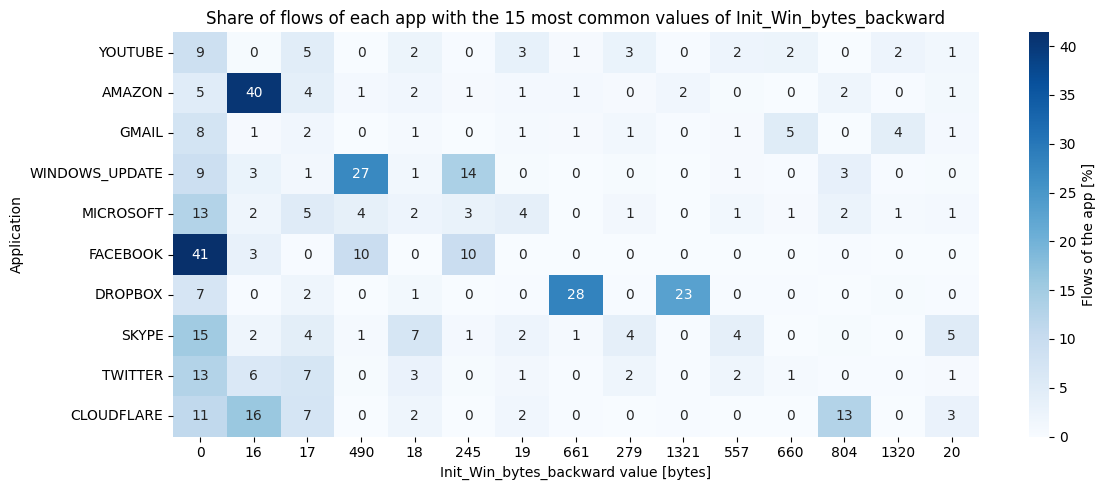

Init_Win_bytes_backward between 1 and 1023 bytes: 79.1% of the flows


In [18]:
col = "Init_Win_bytes_backward"
top_values = X_train[col].value_counts().head(15).index
value_share = pd.crosstab(y_train, X_train[col], normalize="index").loc[APPS, top_values] * 100

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(value_share, cmap="Blues", annot=True, fmt=".0f", vmin=0, cbar_kws={"label": "Flows of the app [%]"}, ax=ax)
ax.set_xlabel(f"{col} value [bytes]")
ax.set_ylabel("Application")
ax.set_title(f"Share of flows of each app with the 15 most common values of {col}")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "eda_init_win_backward.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"{col} between 1 and 1023 bytes: {X_train[col].between(1, 1023).mean() * 100:.1f}% of the flows")

`Init_Win_bytes_backward` is the TCP window in the first packet sent by the responder (the server, or the Squid proxy
for the flows to port 3128). Its values depend a lot on the app: 40% of the AMAZON flows have value 16, 41% of the
WINDOWS_UPDATE flows have 490 or 245, 51% of the DROPBOX flows 661 or 1321. The value 0 also includes the flows where
the window was not observed (the `-1` we replaced in 1.2), and it's the most common one for FACEBOOK.

79% of the values are below 1024 bytes, which is way too small for a real initial window (the client values in
`Init_Win_bytes_forward` are usually 5840, 8192, 14600 or 65535). The reason is that only SYN and SYN-ACK have the
window unscaled, while the following segments have it divided by the window scale factor negotiated in the handshake
[4]. So in most flows this value doesn't come from the SYN-ACK, it depends on the scale factor and on the state of the
connection. It's very informative, but it's not a clean fingerprint of the server.

`Init_Win_bytes_forward` is the same field but set by the client. Unlike the server window, the attacker can control it
directly, so a rare value of it is a good candidate for the backdoor trigger (Section 4).

**Exact values vs ranges.** The AUC (like the Pearson or Spearman correlation with the 0/1 label) treats a feature as
ordered and only checks if an app has bigger or smaller values. For `Init_Win_bytes_backward` this doesn't make much
sense: 490 and 486 are close numbers but they can come from completely different servers. To see where the information
is, `exact_vs_range_mi` computes the MI with the app label in two ways (on the full training set):
- exact values: every distinct value is a category (like one-hot encoding the feature);
- ranges: the feature is split in 20 quantile bins, so we only keep the order (with many ties some bins get merged).

Both use the Miller-Madow correction, because the bias of the MI estimate grows with the number of distinct values:
without it, the MI on the exact values would always be at least the one on the ranges and the comparison would not
mean much. As a control we also add three packet counts (`Total.Fwd.Packets`, `Total.Backward.Packets`,
`act_data_pkt_fwd`): they also have thousands of distinct values, but there is no reason why a specific count should
identify an app. We only do this for features with less than 10,000 distinct values, because the timing features have
hundreds of thousands of almost unique values and each "exact value" would contain 1 or 2 flows. So the table has the
top-15 MI features with < 10,000 values, plus the three controls.

In [19]:
top_mi_features = mi.head(15).index
few_values = [f for f in top_mi_features if X_train[f].nunique() < 10_000]
# control: packet counts, many distinct values but normal quantities
controls = ["Total.Fwd.Packets", "Total.Backward.Packets", "act_data_pkt_fwd"]
mi_values = exact_vs_range_mi(X_train[few_values + controls], y_train, n_bins=20)
mi_values["exact / ranges"] = mi_values["mi_exact_values"] / mi_values["mi_quantile_bins"]
mi_values["best max(auc, 1 - auc)"] = np.maximum(auc.loc[few_values + controls], 1 - auc.loc[few_values + controls]).max(axis=1)
mi_values.round(3)

,distinct_values,mi_exact_values,mi_quantile_bins,exact / ranges,"best max(auc, 1 - auc)"
Init_Win_bytes_backward,5227.0,0.702,0.284,2.473,0.698
Fwd.Packet.Length.Max,3934.0,0.699,0.337,2.077,0.732
Bwd.Packet.Length.Max,7692.0,0.659,0.256,2.575,0.666
Max.Packet.Length,7909.0,0.631,0.232,2.722,0.656
Init_Win_bytes_forward,8457.0,0.392,0.161,2.430,0.786
Total.Fwd.Packets,3861.0,0.161,0.148,1.085,0.666
Total.Backward.Packets,5274.0,0.128,0.143,0.897,0.746
act_data_pkt_fwd,2906.0,0.093,0.100,0.931,0.698


Comments:
- For the initial windows and the max packet lengths, the exact values give 2-2.7 times the information of the ranges,
  while for the control features the two are almost the same (ratio 0.9-1.1), so the difference is not just because of
  the finer partition. Their best AUC is only around 0.65-0.8. So these features are numeric but partly categorical:
  specific values are signatures of the TCP endpoints (windows) or of fixed-size protocol messages (max sizes, these
  are the horizontal and vertical lines in the scatter plots below). The MI on the ranges is not 0 though, so the order
  still matters a bit.
- For the other top features this is not the case. The packet length means, the totals and the timing features have high
  MI because the apps are in different ranges of values, often in the middle of the distribution (an app with medium
  durations is neither "bigger" nor "smaller" than the rest). The one-vs-rest AUC misses this too, but it has nothing to
  do with specific values.
- For the models: one-hot encoding these features is not practical (thousands of values, many seen only a few times).
  Trees don't need it, they can isolate a value with two splits. For the MLP instead, after log1p and Min-Max two values
  like 486 and 490 become almost the same input. If the MLP doesn't perform well, in Section 2 we could add one-hot
  indicators for the most frequent values of these features (like we did for the ports) and put the rest in "Other".

### Correlation analysis

We compute both Pearson (linear dependence) and Spearman (Pearson on the ranks, so monotonic dependence) on the 54
continuous features. To make the heatmaps easier to read, rows and columns are ordered with hierarchical clustering on
the distance $1 - |r_s|$ (`feature_clusters`), so groups of correlated features show up as blocks on the diagonal.

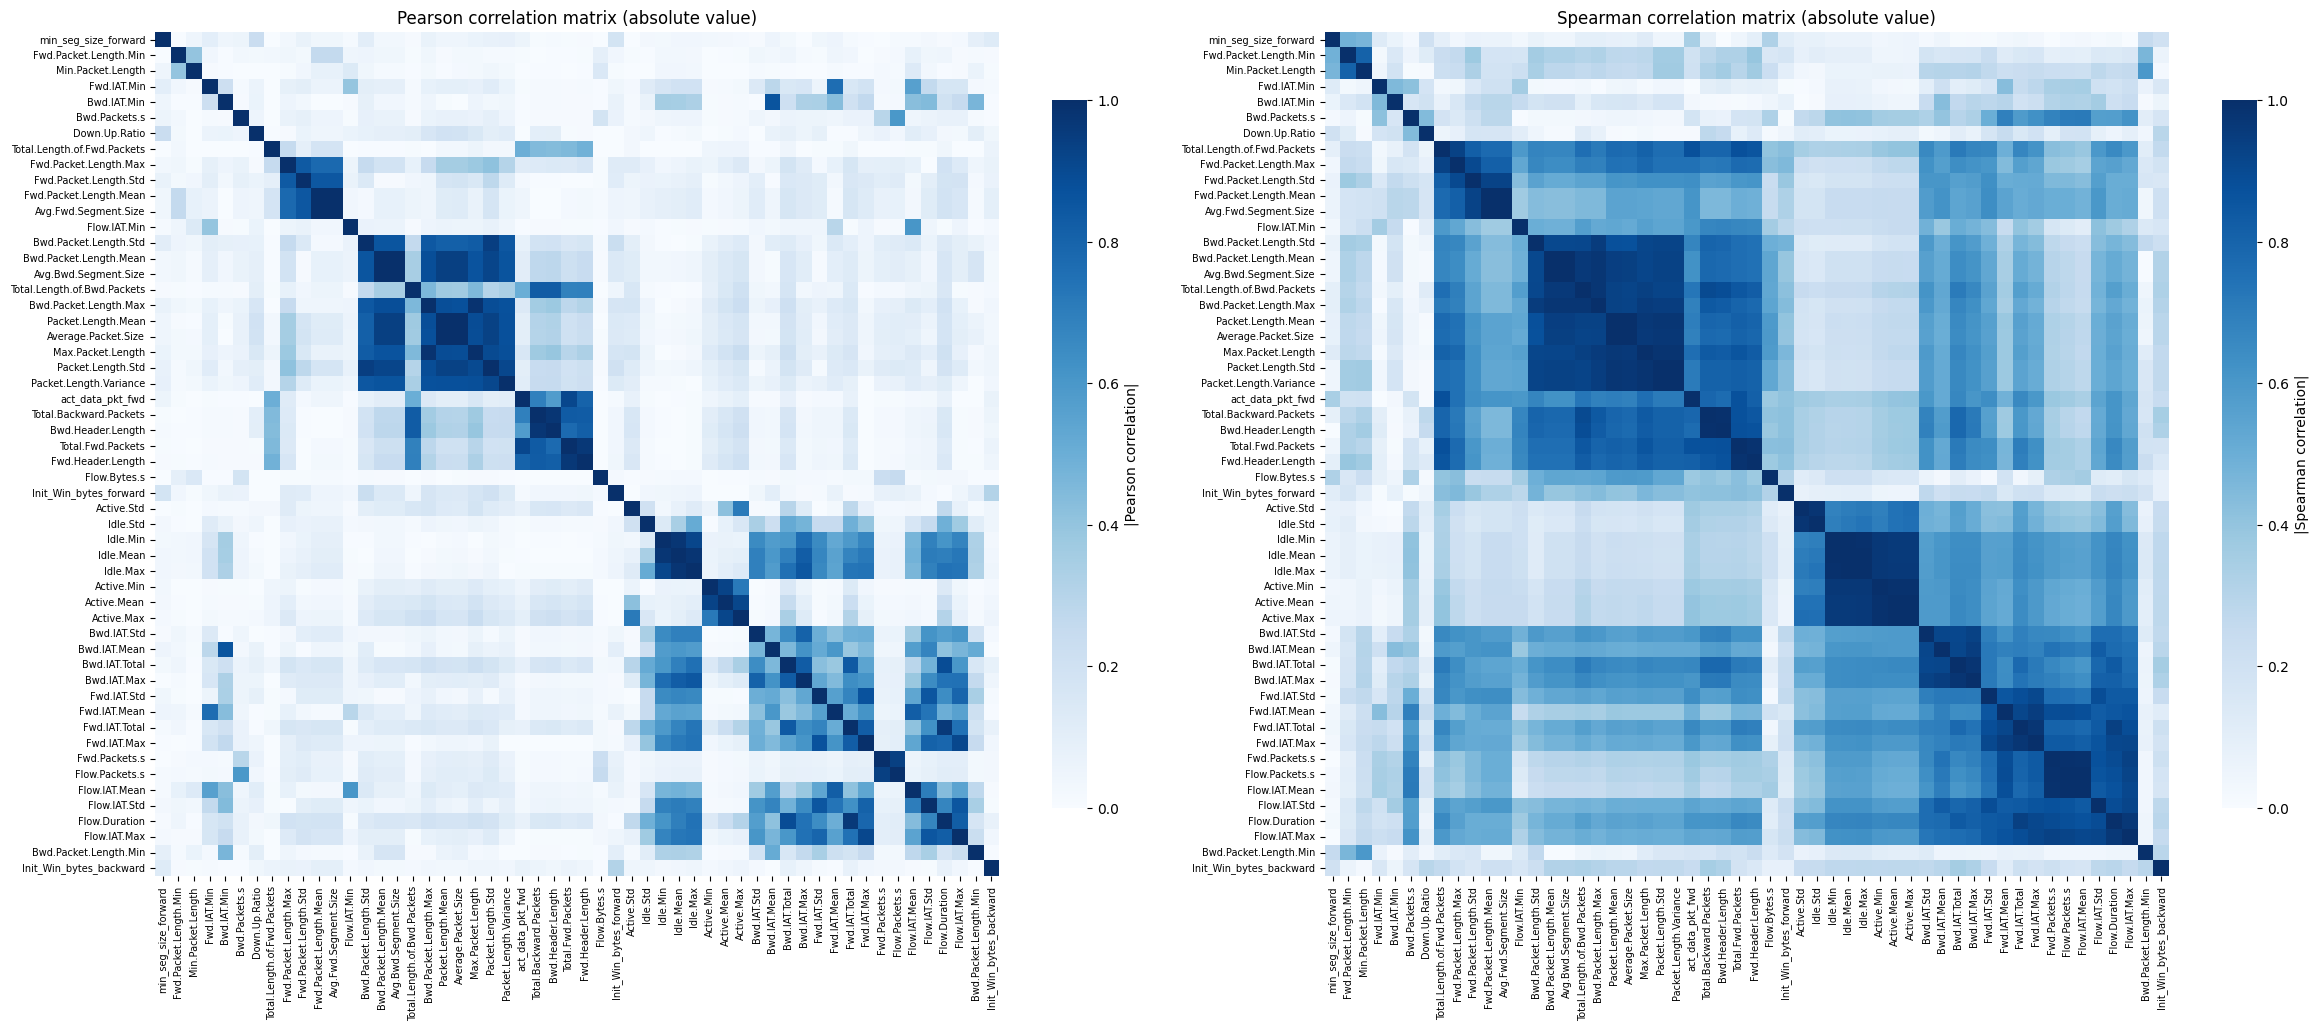

In [20]:
corr_p = X_train[cont_cols].corr()
corr_s = X_train[cont_cols].corr(method="spearman")
clusters = feature_clusters(corr_s, threshold=0.9)
order = clusters.index

fig, axes = plt.subplots(1, 2, figsize=(24, 11))
for ax, corr, name in zip(axes, [corr_p, corr_s], ["Pearson", "Spearman"]):
    sns.heatmap(corr.loc[order, order].abs(), cmap="Blues", vmin=0, vmax=1, square=True, xticklabels=True,
                yticklabels=True, cbar_kws={"label": f"|{name} correlation|", "shrink": 0.7}, ax=ax)
    ax.set_title(f"{name} correlation matrix (absolute value)")
    ax.tick_params(labelsize=7)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "eda_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

In [21]:
pairs = correlation_pairs(pearson=corr_p, spearman=corr_s, pearson_log1p=np.log1p(X_train[cont_cols]).corr())
methods = ["pearson", "spearman", "pearson_log1p"]
pd.DataFrame({
    "pairs with |corr| >= 0.9": (pairs[methods].abs() >= 0.9).sum(),
    "mean |corr|": pairs[methods].abs().mean(),
}).round(3)

,pairs with |corr| >= 0.9,mean |corr|
pearson,26,0.161
spearman,87,0.424
pearson_log1p,89,0.449


In [22]:
# pairs where Spearman is much higher than Pearson
pairs["spearman - pearson"] = pairs["spearman"].abs() - pairs["pearson"].abs()
both_nonzero = (X_train["Active.Min"] > 0) & (X_train["Idle.Max"] > 0)
print(f"Spearman Active.Min vs Idle.Max: all flows {corr_s.loc['Active.Min', 'Idle.Max']:.2f}, "
      f"flows where both are non-zero {X_train.loc[both_nonzero, ['Active.Min', 'Idle.Max']].corr('spearman').iloc[0, 1]:.2f}")
pairs.sort_values("spearman - pearson", ascending=False).head(8).round(3)

Spearman Active.Min vs Idle.Max: all flows 0.97, flows where both are non-zero -0.18


,feature_1,feature_2,pearson,spearman,pearson_log1p,spearman - pearson
651,Flow.Packets.s,Flow.IAT.Mean,-0.064,-0.999,-0.985,0.935
705,Flow.IAT.Mean,Fwd.Packets.s,-0.058,-0.991,-0.969,0.933
1423,Active.Min,Idle.Max,0.060,0.965,0.899,0.905
1421,Active.Min,Idle.Mean,0.065,0.965,0.899,0.901
1424,Active.Min,Idle.Min,0.067,0.967,0.899,0.899
1420,Active.Max,Idle.Min,0.065,0.958,0.937,0.893
1409,Active.Mean,Idle.Min,0.073,0.959,0.939,0.886
1406,Active.Mean,Idle.Mean,0.086,0.960,0.941,0.874


In [23]:
feature_groups = [list(g) for g in clusters.groupby(clusters).groups.values() if len(g) > 1]
print(f"{len(cont_cols)} continuous features -> {clusters.nunique()} groups where every pair has |r_s| >= 0.9")
print(f"Groups with more than one feature ({len(feature_groups)}):")
for group in feature_groups:
    print(" -", ", ".join(group))

54 continuous features -> 27 groups where every pair has |r_s| >= 0.9
Groups with more than one feature (11):
 - Total.Length.of.Fwd.Packets, Fwd.Packet.Length.Max
 - Fwd.Packet.Length.Std, Fwd.Packet.Length.Mean, Avg.Fwd.Segment.Size
 - Bwd.Packet.Length.Mean, Avg.Bwd.Segment.Size, Total.Length.of.Bwd.Packets, Bwd.Packet.Length.Max, Packet.Length.Mean, Average.Packet.Size, Max.Packet.Length, Packet.Length.Std, Packet.Length.Variance
 - Total.Backward.Packets, Bwd.Header.Length
 - Total.Fwd.Packets, Fwd.Header.Length
 - Active.Std, Idle.Std
 - Idle.Min, Idle.Mean, Idle.Max, Active.Min, Active.Mean, Active.Max
 - Bwd.IAT.Std, Bwd.IAT.Mean, Bwd.IAT.Total, Bwd.IAT.Max
 - Fwd.IAT.Mean, Fwd.IAT.Total, Fwd.IAT.Max
 - Fwd.Packets.s, Flow.Packets.s, Flow.IAT.Mean
 - Flow.Duration, Flow.IAT.Max


In [24]:
# pairs with Spearman ~1: are they actually the same feature?
near_identical = pairs.loc[pairs["spearman"].abs() >= 0.999, ["feature_1", "feature_2", "pearson", "spearman"]].copy()
near_identical["max_relative_difference"] = [
    ((X_train[a] - X_train[b]).abs() / X_train[a].abs().clip(lower=1)).max()
    for a, b in zip(near_identical["feature_1"], near_identical["feature_2"])
]

# the variance should be std^2
rel_err = ((X_train["Packet.Length.Std"] ** 2 - X_train["Packet.Length.Variance"]).abs()
           / X_train["Packet.Length.Variance"].clip(lower=1))
print(f"max relative difference between Packet.Length.Std^2 and Packet.Length.Variance = {rel_err.max():.2e}")
near_identical.sort_values("spearman", key=abs, ascending=False)

max relative difference between Packet.Length.Std^2 and Packet.Length.Variance = 1.40e-06


,feature_1,feature_2,pearson,spearman,max_relative_difference
557,Bwd.Packet.Length.Mean,Avg.Bwd.Segment.Size,1.000000,1.000000,9.578654e-07
382,Fwd.Packet.Length.Mean,Avg.Fwd.Segment.Size,1.000000,1.000000,8.941049e-07
1278,Packet.Length.Std,Packet.Length.Variance,0.910520,1.000000,5.172765e+03
1404,Active.Mean,Active.Max,0.915872,0.999488,1.998957e+01
1263,Packet.Length.Mean,Average.Packet.Size,0.999288,0.999270,5.000004e-01


Comments:
- On the raw data Pearson underestimates the dependence: mean $|r|$ = 0.16 vs 0.42 for Spearman, and 26 pairs with
  $|r| \ge 0.9$ vs 87. The extreme values in the tails dominate Pearson. The clearest example is `Flow.Packets.s` vs
  `Flow.IAT.Mean`: $r = -0.06$ but $r_s = -0.999$, because the packet rate is basically the inverse of the mean IAT
  (monotonic but not linear). After `log1p`, Pearson (mean 0.45, 89 pairs) is very close to Spearman, so in the space
  seen by the models these relations become almost linear.
- Some Spearman values are high only because of shared zeros: `Active.*` and `Idle.*` are 0 together in ~77% of the
  flows, and these ties alone give $r_s$ around 0.96-0.97. If we only take the flows where both are non-zero, $r_s$
  between `Active.Min` and `Idle.Max` is only -0.18 (printed above the table).
- There is a lot of redundancy: the 54 continuous features form 27 groups where every pair has $|r_s| \ge 0.9$ (sizes and
  lengths, packet counts and header lengths, IAT statistics, active/idle). This is not a problem for trees and not a big
  one for the MLP, but it matters for the attacks in Section 3: if we perturb a feature but not the ones correlated to
  it, the resulting flow is not consistent.
- Three features are copies of other ones (last table). `Avg.Fwd.Segment.Size` and `Avg.Bwd.Segment.Size` have
  $r = r_s = 1$ with `Fwd.Packet.Length.Mean` and `Bwd.Packet.Length.Mean`, and the values are the same up to float
  rounding (relative difference ~1e-6), that's why the exact duplicate check in 1.2 didn't find them.
  `Packet.Length.Variance` has $r_s = 1$ but $r = 0.91$ with `Packet.Length.Std`, which makes sense since the variance
  is the std squared. The other pairs with $r_s \approx 1$ are actually different features, e.g. `Packet.Length.Mean`
  and `Average.Packet.Size` differ by up to 50% in some flows.

### Distributions of the most informative features

To plot the most interesting features without repeating the same information, `select_non_redundant` goes through the
continuous features sorted by MI (without the 3 copies found above, `REDUNDANT_FEATURES`) and keeps a feature only if
it has $|r_s| < 0.9$ with all the ones already kept. We plot the first 8 as boxplots per app (whiskers at 1.5 IQR; we
don't draw the outliers because they are thousands per app, and we already looked at them above).

Selected features: ['Init_Win_bytes_backward', 'Fwd.Packet.Length.Max', 'Bwd.Packet.Length.Max', 'Fwd.Packet.Length.Mean', 'Flow.IAT.Max', 'Init_Win_bytes_forward', 'Bwd.IAT.Max', 'Fwd.Header.Length']


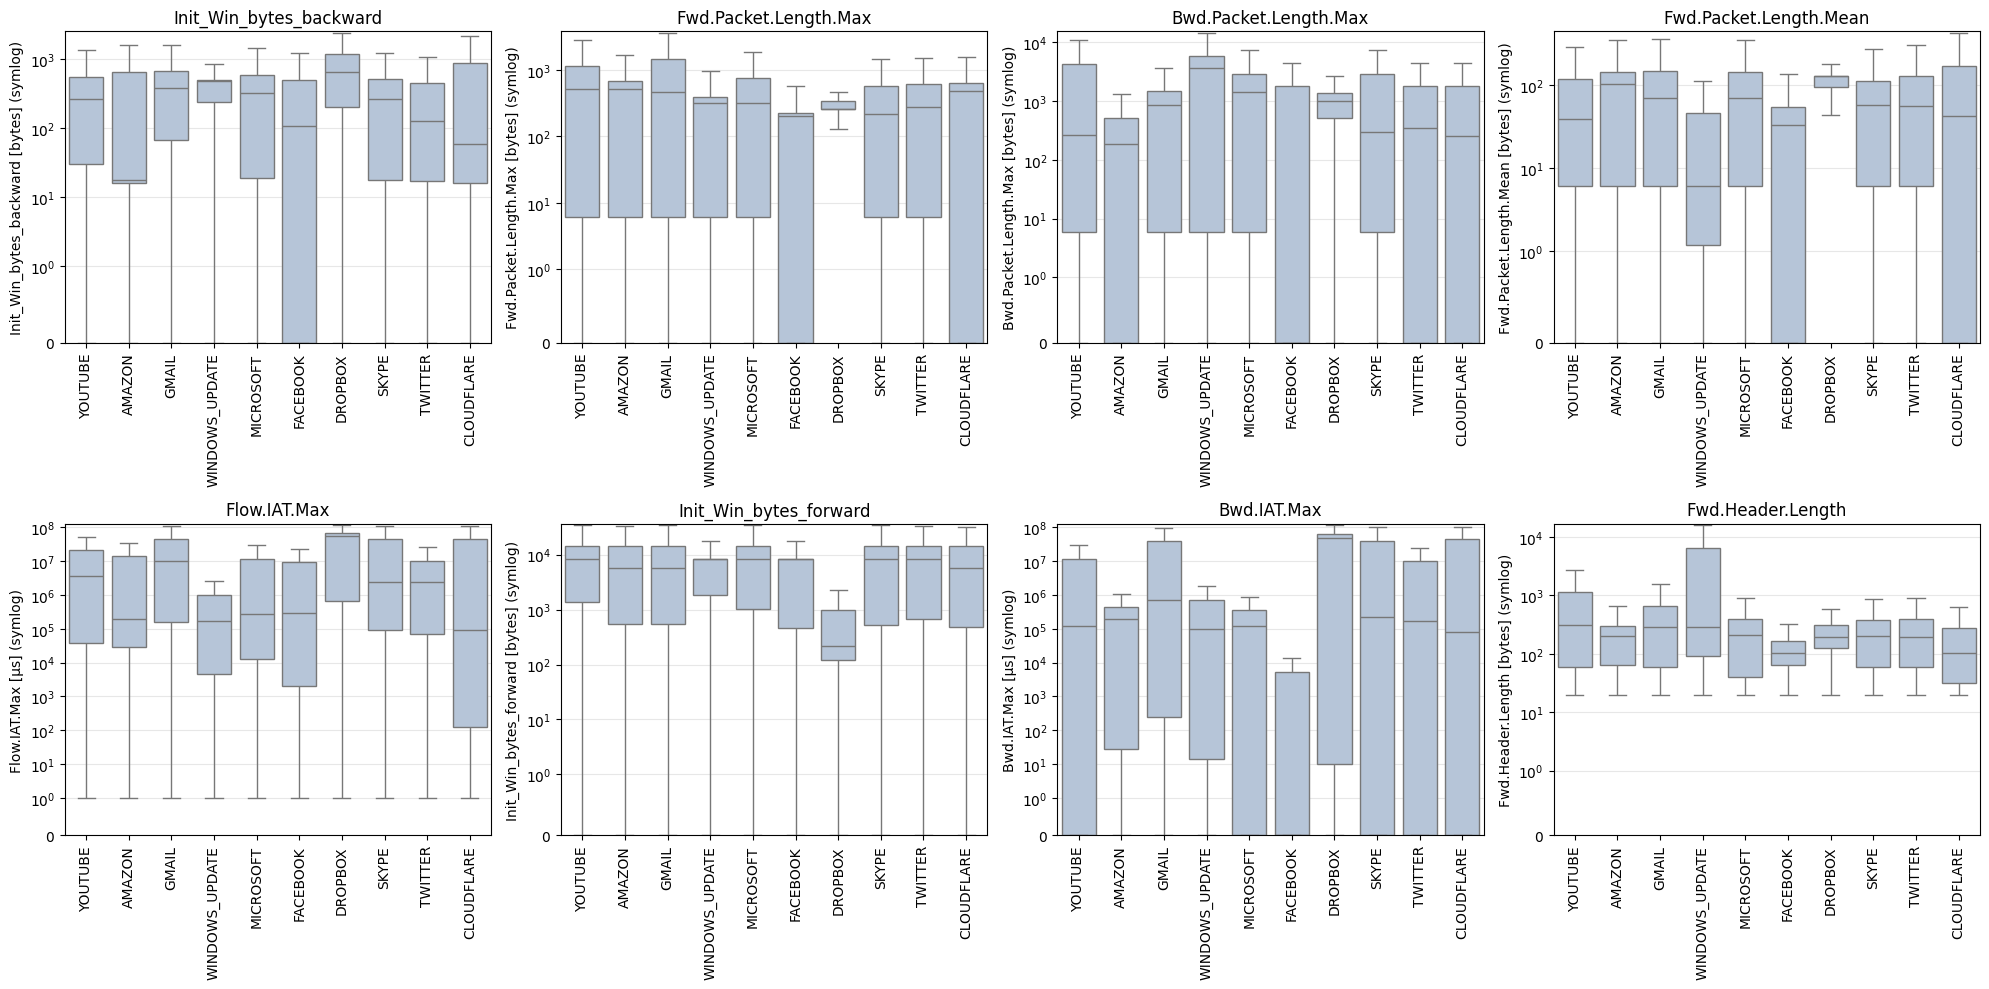

In [25]:
mi_cont = mi[mi.index.isin(cont_cols) & ~mi.index.isin(REDUNDANT_FEATURES)]
top_features = select_non_redundant(mi_cont.index, corr_s, threshold=0.9)[:8]
print("Selected features:", top_features)

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for ax, feature in zip(axes.flat, top_features):
    sns.boxplot(x=y_train, y=X_train[feature], order=APPS, color="lightsteelblue", showfliers=False, linewidth=1, ax=ax)
    ax.set_yscale("symlog", linthresh=1)
    ax.set_ylim(bottom=0)
    ax.set_title(feature)
    ax.set_xlabel("")
    ax.set_ylabel(f"{feature_label(feature)} (symlog)")
    ax.tick_params(axis="x", rotation=90)
    ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "eda_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

Comments (the y axis is log, so each grid line is x10):
- `Init_Win_bytes_backward`: narrow boxes for the apps with a few dominant values (WINDOWS_UPDATE, DROPBOX), very wide
  for YOUTUBE, MICROSOFT and CLOUDFLARE.
- `Fwd.Packet.Length.Max` and `Bwd.Packet.Length.Max`: WINDOWS_UPDATE and MICROSOFT receive much bigger packets than
  the others (median `Bwd.Packet.Length.Max` 3670 and 1436 bytes), while FACEBOOK sends and receives small packets (its
  median backward max is 0, so no payload from the server). DROPBOX has a very narrow forward max, again because of the
  inverted flows. Values above 1500 bytes (Ethernet MTU) are probably due to segmentation offloading at the capture
  point (more TCP segments seen as one packet).
- `Flow.IAT.Max` and `Bwd.IAT.Max`: DROPBOX has the longest silences (tens of seconds), GMAIL and YOUTUBE also have long
  gaps; FACEBOOK has `Bwd.IAT.Max` = 0 in most flows (less than two backward packets).
- `Init_Win_bytes_forward` is similar for most apps (typical client windows 5840, 8192, 14600, 65535), except DROPBOX,
  where the inverted flows report the window of the server.
- `Fwd.Packet.Length.Mean` is lowest for WINDOWS_UPDATE: during the download the client mostly sends small ACKs, which
  also gives it the largest `Fwd.Header.Length` (many forward packets).
- In all the plots the whiskers cover several orders of magnitude and the boxes of different apps overlap: the apps
  differ in the position and in some specific values, but they are not cleanly separated.

### ECDFs

A boxplot summarizes a distribution with only five numbers, so it doesn't show where the values are concentrated. The
ECDF ($\hat F(x)$ = fraction of flows with value $\le x$) shows the whole distribution without choosing bins or a KDE
bandwidth, and it doesn't have the KDE problem at 0 (many features are often exactly 0). A value shared by many flows
shows up as a vertical step, whose height is the % of flows with that value.

We compare two features on the full training set, one panel per app: `Init_Win_bytes_backward`, where the information
is in the exact values, and `Flow.IAT.Max`, where it is in the ranges (see above). In each title there is the two-sample
Kolmogorov-Smirnov statistic (`scipy.stats.ks_2samp`), i.e. the max vertical distance between the two curves (0 = same
distribution, 1 = completely separated). The table compares it with the AUC.

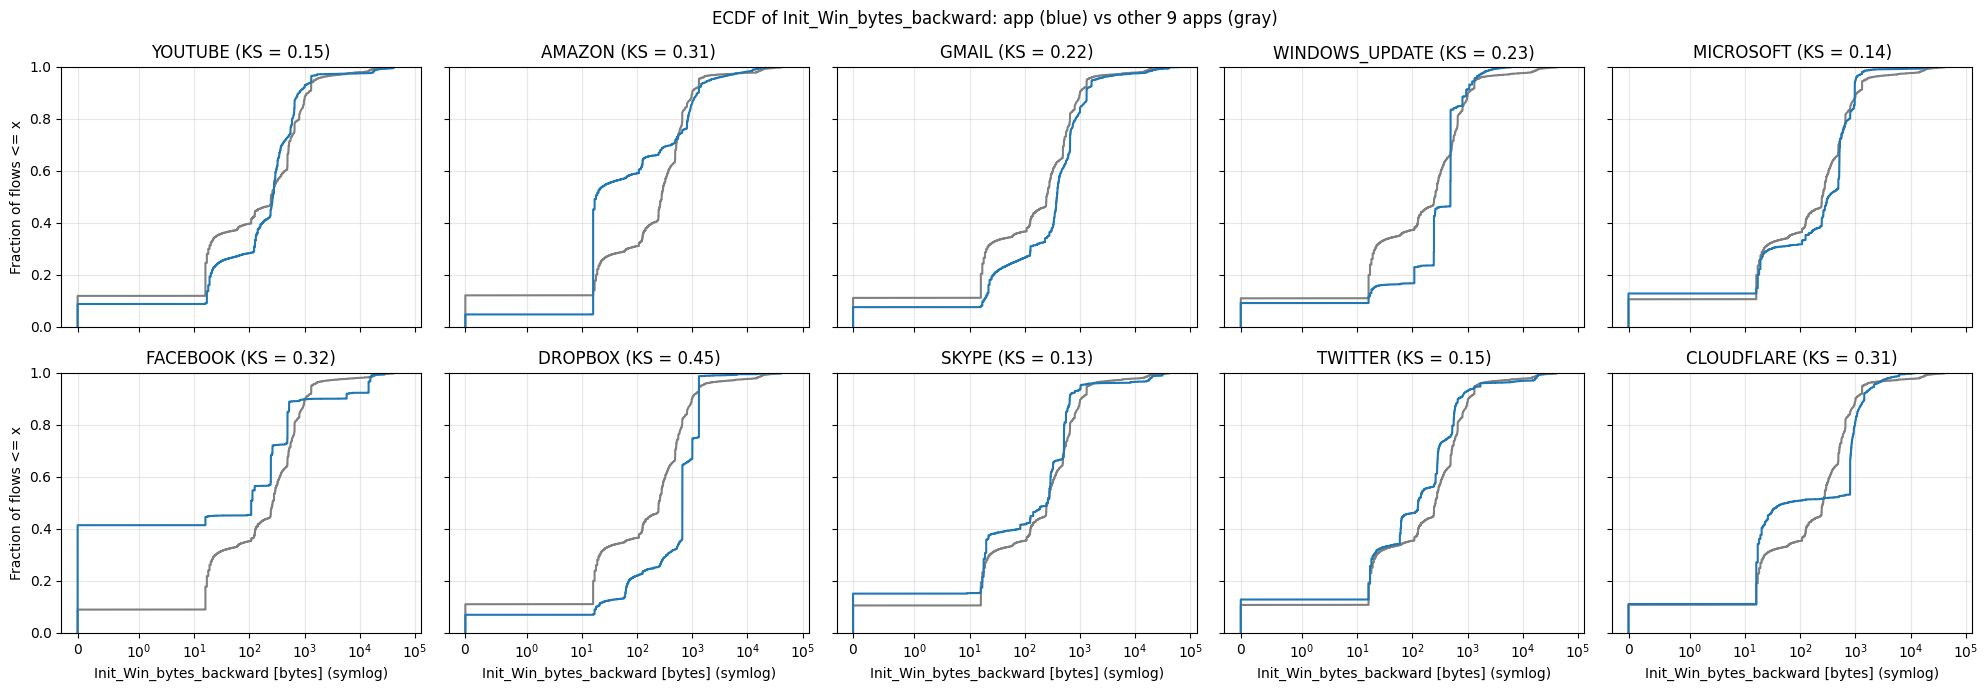

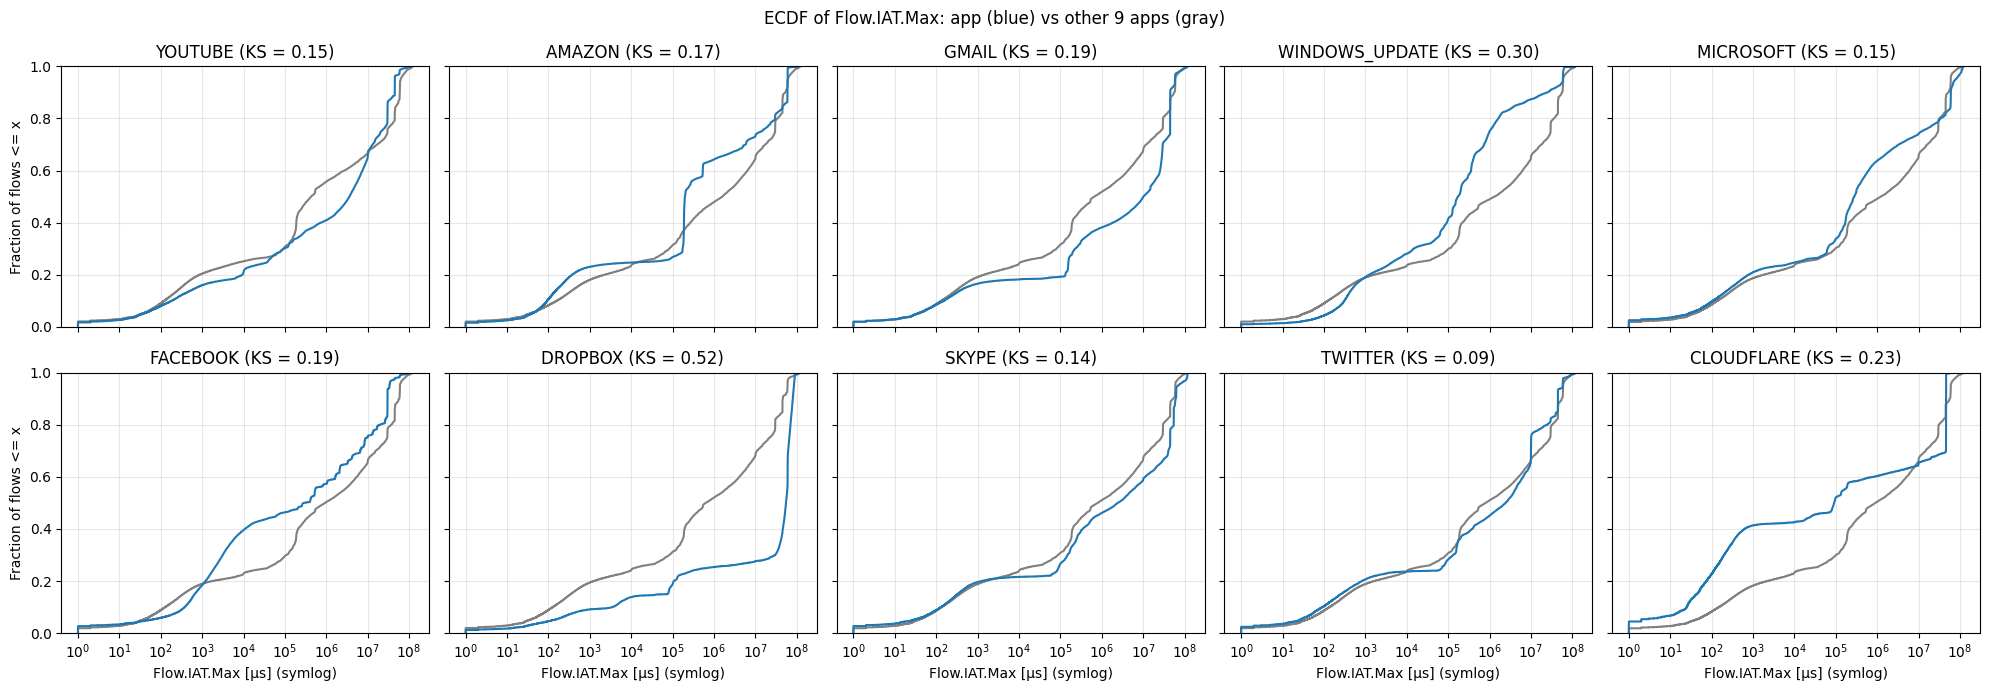

Flow.IAT.Max > 10 s [% of the flows]: {'YOUTUBE': 35.0, 'AMAZON': 27.0, 'GMAIL': 50.0, 'WINDOWS_UPDATE': 13.0, 'MICROSOFT': 26.0, 'FACEBOOK': 25.0, 'DROPBOX': 72.0, 'SKYPE': 41.0, 'TWITTER': 32.0, 'CLOUDFLARE': 35.0}
CLOUDFLARE flows with Flow.IAT.Max in [45.5, 46.5) s: 29.9%
AMAZON flows in [0.1, 0.2] s: 23.6%


Init_Win_bytes_backward       Flow.IAT.Max      
                                    KS   AUC           KS   AUC
YOUTUBE                           0.15  0.51         0.15  0.52
AMAZON                            0.31  0.39         0.17  0.45
GMAIL                             0.22  0.60         0.19  0.58
WINDOWS_UPDATE                    0.23  0.55         0.30  0.39
MICROSOFT                         0.14  0.53         0.15  0.46
FACEBOOK                          0.32  0.36         0.19  0.42
DROPBOX                           0.45  0.70         0.52  0.75
SKYPE                             0.13  0.46         0.14  0.55
TWITTER                           0.15  0.44         0.09  0.50
CLOUDFLARE                        0.31  0.52         0.23  0.42

In [26]:
def plot_ecdf_one_vs_rest(data, labels, feature):
    # one subplot per app: app in blue, other apps in gray, KS statistic in the title
    fig, axes = plt.subplots(2, 5, figsize=(20, 7), sharex=True, sharey=True)
    ks = {}
    for ax, app in zip(axes.flat, APPS):
        is_app = (labels == app).to_numpy()
        app_values, rest_values = data.loc[is_app, feature], data.loc[~is_app, feature]
        sns.ecdfplot(x=rest_values, color="gray", ax=ax)
        sns.ecdfplot(x=app_values, color="tab:blue", ax=ax)
        ks[app] = ks_2samp(app_values, rest_values).statistic
        ax.set_xscale("symlog", linthresh=1)
        ax.set_title(f"{app} (KS = {ks[app]:.2f})")
        ax.grid(True, alpha=0.3)
    for ax in axes[1]:
        ax.set_xlabel(f"{feature_label(feature)} (symlog)")
    for ax in axes[:, 0]:
        ax.set_ylabel("Fraction of flows <= x")
    fig.suptitle(f"ECDF of {feature}: app (blue) vs other 9 apps (gray)")
    fig.tight_layout()
    return fig, pd.Series(ks)


ecdf_comparison = {}
for feature, filename in [("Init_Win_bytes_backward", "eda_ecdf_init_win_backward.png"),
                          ("Flow.IAT.Max", "eda_ecdf_flow_iat_max.png")]:
    fig, ks = plot_ecdf_one_vs_rest(X_train, y_train, feature)
    fig.savefig(PLOTS_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()
    ecdf_comparison[(feature, "KS")] = ks
    ecdf_comparison[(feature, "AUC")] = auc.loc[feature]

# numbers used in the comments below
iat_s = X_train["Flow.IAT.Max"] / 1e6
print("Flow.IAT.Max > 10 s [% of the flows]:", ((iat_s > 10).groupby(y_train).mean() * 100).round(0).loc[APPS].to_dict())
print(f"CLOUDFLARE flows with Flow.IAT.Max in [45.5, 46.5) s: {iat_s[y_train == 'CLOUDFLARE'].between(45.5, 46.5, inclusive='left').mean() * 100:.1f}%")
print(f"AMAZON flows in [0.1, 0.2] s: {iat_s[y_train == 'AMAZON'].between(0.1, 0.2).mean() * 100:.1f}%")
pd.DataFrame(ecdf_comparison).round(2)

Comments:
- `Init_Win_bytes_backward` looks like a staircase: the vertical steps are the specific values we saw in the heatmap (the
  step at 16 is 40% of AMAZON, 245 and 490 are 41% of WINDOWS_UPDATE, 661 and 1321 are 51% of DROPBOX, 0 is 41% of
  FACEBOOK). The gray curve is a staircase too, since it's a mix of the other apps.
- Here KS finds something that the AUC doesn't. For CLOUDFLARE the curves are far apart (KS = 0.31) but they cross, so
  the app doesn't have overall bigger or smaller values and the AUC is 0.52, like there was no separation. Same for
  WINDOWS_UPDATE (KS = 0.23, AUC = 0.55). This is the non-monotonic dependence we found with the MI.
- `Flow.IAT.Max` is mostly smooth and the apps differ in where most of the values are. DROPBOX is the most separated
  (KS = 0.52): 72% of its flows have a silence longer than 10 s, against 13-50% for the other apps. WINDOWS_UPDATE has
  shorter gaps than the rest (downloads). But there are some steps here too: 30% of the CLOUDFLARE flows have a max gap
  of 46 s and 24% of the AMAZON flows a gap between 0.1 and 0.2 s. They look like fixed timeouts of the protocols or of
  the servers, so again specific values, but on a feature that the attacker can change just by delaying packets.

### Scatter plots

Again one panel per app (app vs rest). To give the same weight to all the apps we use a balanced sample of 2,000
training flows per app (with all the 400k flows the plot would be just a big blob). We show two pairs: max packet length
in the two directions, and duration vs throughput.

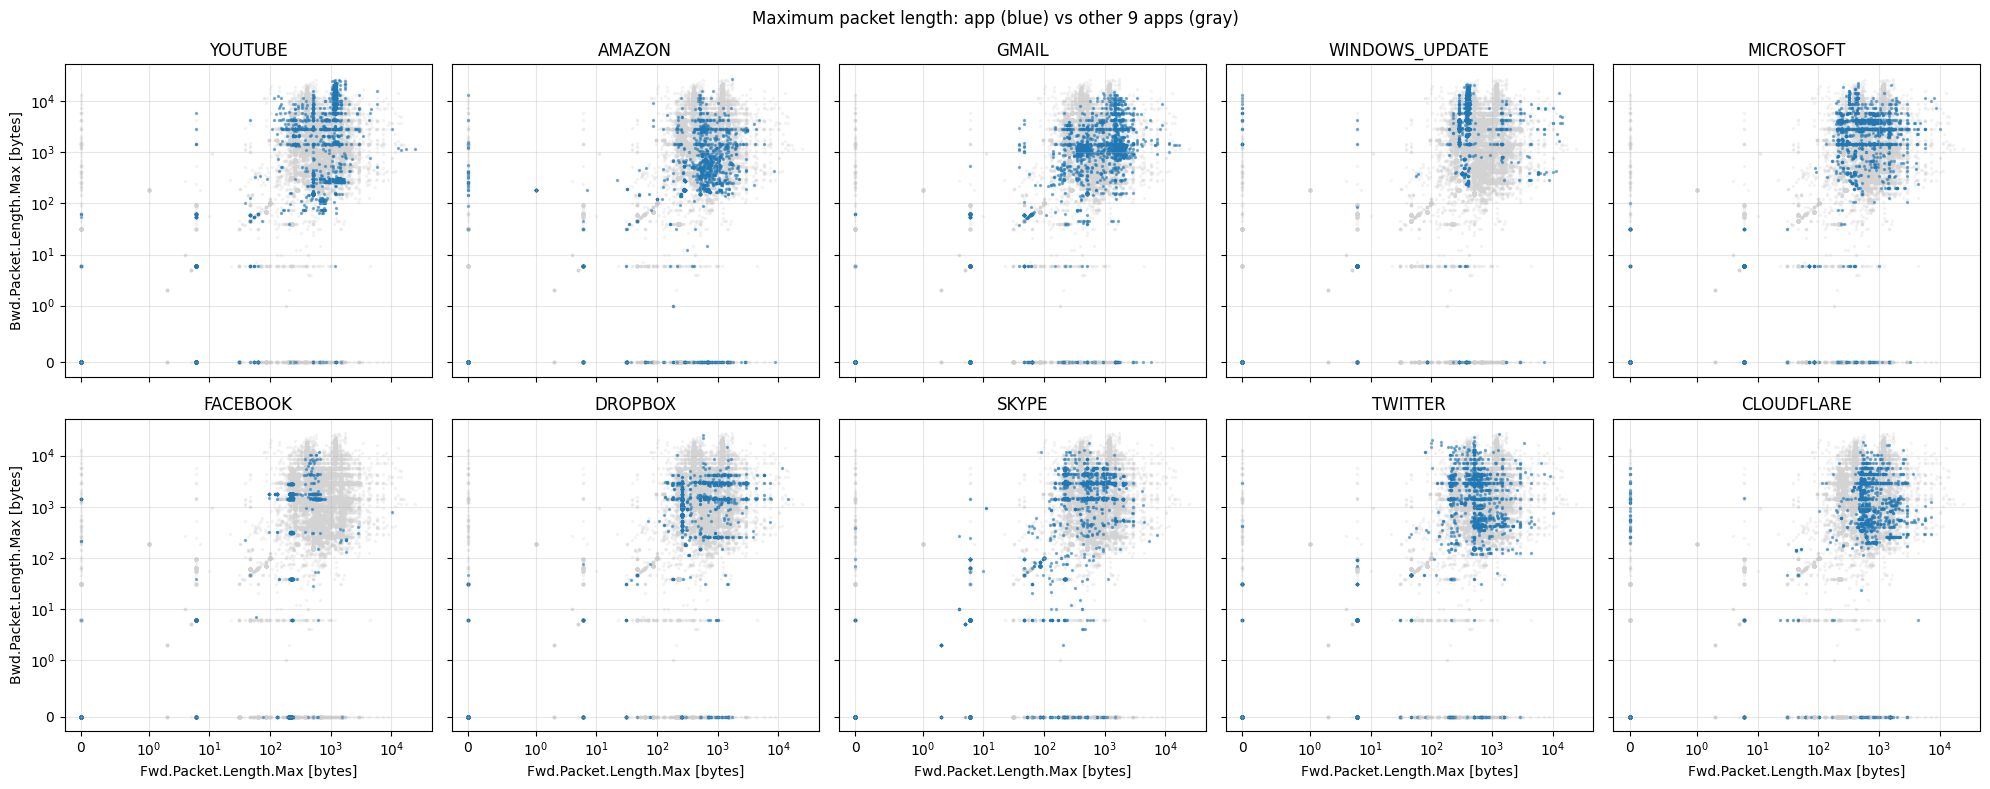

In [27]:
def plot_one_vs_rest(data, labels, x, y, title, log=True):
    # one subplot per app: app in blue, other apps in gray
    fig, axes = plt.subplots(2, 5, figsize=(20, 8), sharex=True, sharey=True)
    for ax, app in zip(axes.flat, APPS):
        is_app = (labels == app).to_numpy()
        ax.scatter(data.loc[~is_app, x], data.loc[~is_app, y], s=2, alpha=0.2, color="lightgray")
        ax.scatter(data.loc[is_app, x], data.loc[is_app, y], s=2, alpha=0.5, color="tab:blue")
        if log:
            ax.set_xscale("symlog", linthresh=1)
            ax.set_yscale("symlog", linthresh=1)
        ax.set_title(app)
        ax.grid(True, alpha=0.3)
    for ax in axes[1]:
        ax.set_xlabel(feature_label(x))
    for ax in axes[:, 0]:
        ax.set_ylabel(feature_label(y))
    fig.suptitle(f"{title}: app (blue) vs other 9 apps (gray)")
    fig.tight_layout()
    return fig


sample_X = X_train.groupby(y_train).sample(n=2000, random_state=42)
sample_y = y_train.loc[sample_X.index]

fig = plot_one_vs_rest(sample_X, sample_y, "Fwd.Packet.Length.Max", "Bwd.Packet.Length.Max", "Maximum packet length")
fig.savefig(PLOTS_DIR / "eda_scatter_packet_length.png", dpi=150, bbox_inches="tight")
plt.show()

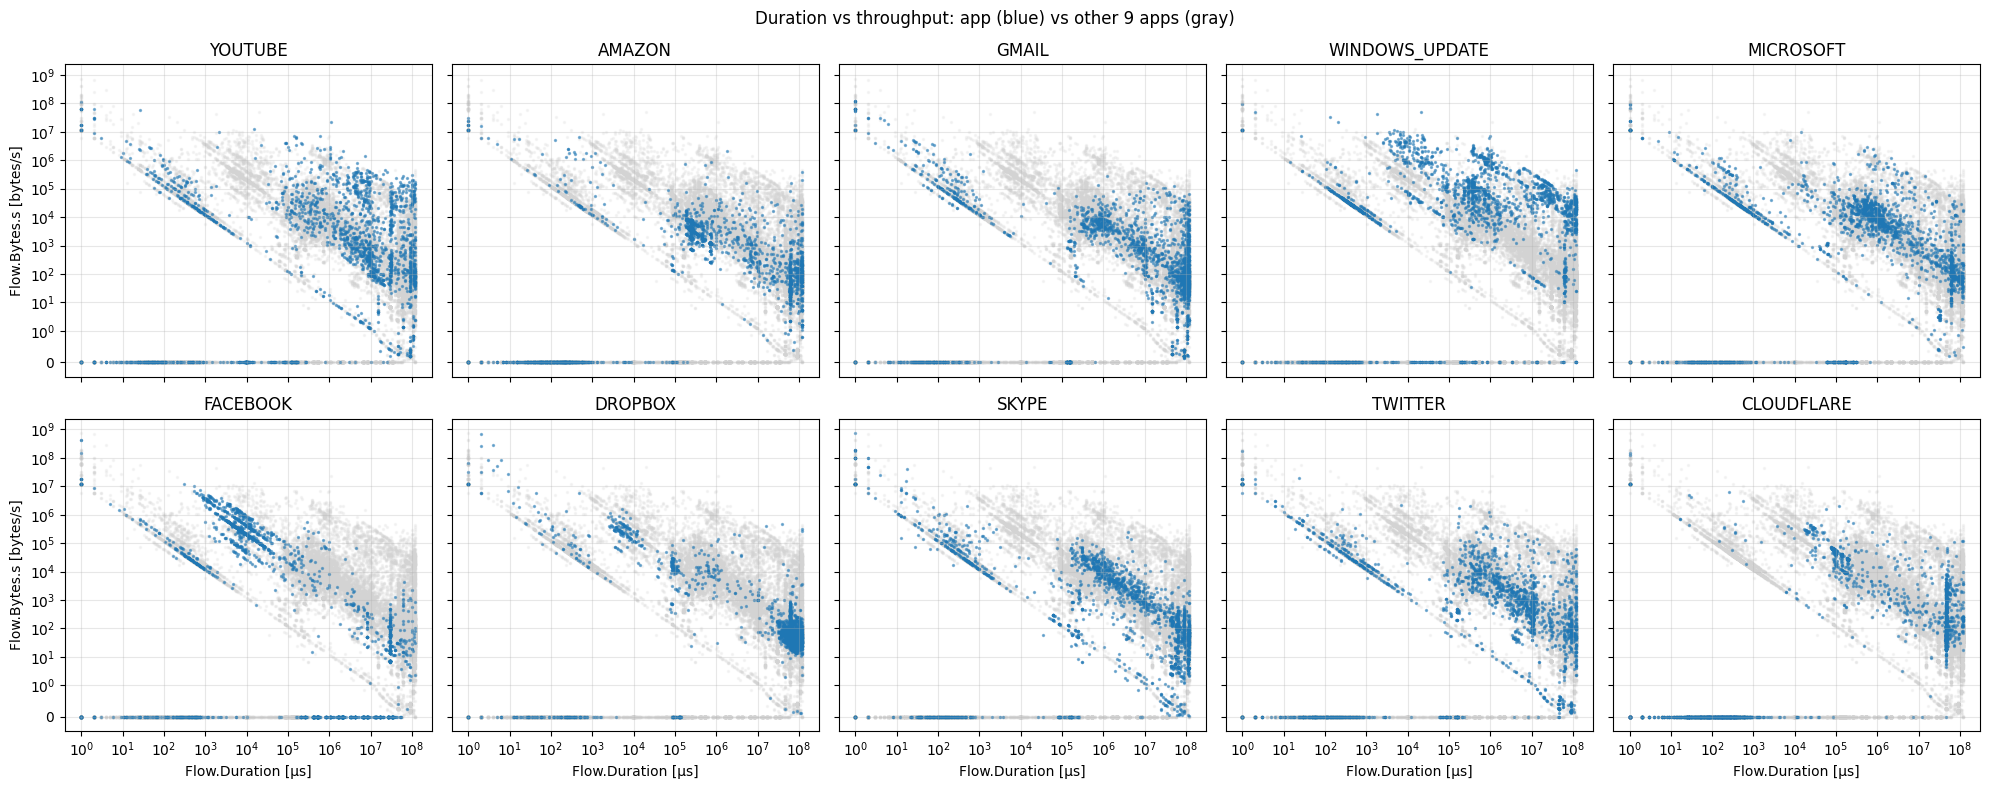

In [28]:
fig = plot_one_vs_rest(sample_X, sample_y, "Flow.Duration", "Flow.Bytes.s", "Duration vs throughput")
fig.savefig(PLOTS_DIR / "eda_scatter_duration_throughput.png", dpi=150, bbox_inches="tight")
plt.show()

Comments:
- Max packet length: the points form horizontal and vertical lines, because many flows have exactly the same max size
  (fixed-size protocol messages). WINDOWS_UPDATE and MICROSOFT are in the region of big backward packets, FACEBOOK and
  DROPBOX are concentrated on a few sizes, while YOUTUBE, AMAZON and GMAIL cover almost everything. The flows on the
  axes have no payload in one of the two directions.
- Duration vs throughput: since `Flow.Bytes.s` = total bytes / duration, flows with the same number of bytes are on a
  line with slope -1 in log-log scale. So each diagonal is an exchange of fixed size repeated many times (handshakes,
  keep-alives, small requests). DROPBOX is on the right edge (flows of ~1e8 µs, close to the 120 s timeout, with low
  throughput), WINDOWS_UPDATE is in the high-throughput region and FACEBOOK is on a few diagonals. The flows with
  `Flow.Bytes.s` = 0 have no payload at all.
- In both plots most apps are inside the gray cloud, so two features are not enough, but the apps occupy different
  regions and lines that trees and MLPs can use.

### PCA

With PCA we want to see how redundant the features are and if the apps separate along the directions of max variance.
As seen in class we have to standardize first, otherwise the features with a bigger range dominate the variance. We
apply `StandardScaler` to `X_train_scaled` (log1p + Min-Max): since Min-Max is a linear transformation, this is the
same as standardizing the log features, so the tails don't dominate the components.

Components for 80% of the variance: 8 / 67
Components for 90% of the variance: 14 / 67
Components for 95% of the variance: 19 / 67
Components with eigenvalue > 1 (Kaiser rule): 11


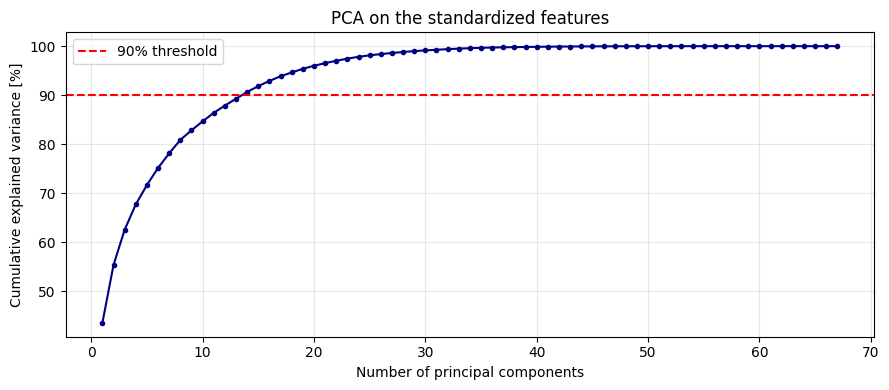

In [29]:
X_std = StandardScaler().fit_transform(X_train_scaled)
pca = PCA(random_state=15).fit(X_std)
cumul_var = np.cumsum(pca.explained_variance_ratio_) * 100

for threshold in (80, 90, 95):
    print(f"Components for {threshold}% of the variance: {np.argmax(cumul_var >= threshold) + 1} / {X_std.shape[1]}")
print(f"Components with eigenvalue > 1 (Kaiser rule): {(pca.explained_variance_ > 1).sum()}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, len(cumul_var) + 1), cumul_var, marker="o", markersize=3, color="navy")
ax.axhline(y=90, color="r", linestyle="--", label="90% threshold")
ax.set_xlabel("Number of principal components")
ax.set_ylabel("Cumulative explained variance [%]")
ax.set_title("PCA on the standardized features")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS_DIR / "eda_pca_variance.png", dpi=150, bbox_inches="tight")
plt.show()

In [30]:
# explained variance of each component, up to 95%
n_show = np.argmax(cumul_var >= 95) + 1
pd.DataFrame({
    "eigenvalue": pca.explained_variance_[:n_show],
    "explained_variance_%": pca.explained_variance_ratio_[:n_show] * 100,
    "cumulative_variance_%": cumul_var[:n_show],
}, index=pd.RangeIndex(1, n_show + 1, name="n_components")).round(2)

,eigenvalue,explained_variance_%,cumulative_variance_%
n_components,,,
1,29.17,43.54,43.54
2,7.93,11.83,55.38
3,4.81,7.18,62.56
4,3.46,5.16,67.72
5,2.65,3.96,71.68
6,2.34,3.49,75.17
7,1.99,2.98,78.14
8,1.83,2.74,80.88
9,1.31,1.95,82.83


In [31]:
# loading scores = components^T * sqrt(eigenvalues), i.e. correlation between feature and PC
n_comp = 10
pca_10 = PCA(n_components=n_comp, random_state=15).fit(X_std)
loadings = pd.DataFrame(
    data=pca_10.components_.T * np.sqrt(pca_10.explained_variance_),
    columns=[f"PC{i}" for i in range(1, n_comp + 1)],
    index=X_train_scaled.columns,
)
# top 8 features of the first 6 PCs (explained variance in the header)
pd.DataFrame({
    f"{pc} ({var:.1f}%)": [f"{f} ({loadings.loc[f, pc]:+.2f})" for f in loadings[pc].abs().nlargest(8).index]
    for pc, var in zip(loadings.columns[:6], pca_10.explained_variance_ratio_[:6] * 100)
})

,PC1 (43.5%),PC2 (11.8%),PC3 (7.2%),PC4 (5.2%),PC5 (4.0%),PC6 (3.5%)
0,Max.Packet.Length (+0.93),Idle.Max (+0.77),Bwd.Packets.s (+0.54),min_seg_size_forward (+0.80),Destination.Port_Other (+0.61),Init_Win_bytes_backward_missing (+0.60)
1,Packet.Length.Std (+0.93),Idle.Mean (+0.77),Down.Up.Ratio (+0.51),Destination.Port_3128 (-0.74),Bwd.Packet.Length.Min (+0.58),Init_Win_bytes_backward (-0.59)
2,Bwd.IAT.Total (+0.93),Idle.Min (+0.77),Flow.IAT.Mean (-0.50),Min.Packet.Length (-0.66),Fwd.PSH.Flags (+0.53),Down.Up.Ratio (-0.53)
3,Packet.Length.Variance (+0.93),Active.Max (+0.68),Fwd.IAT.Min (-0.50),Fwd.Packet.Length.Min (-0.60),Bwd.IAT.Min (+0.40),Destination.Port_3128 (-0.33)
4,Total.Length.of.Fwd.Packets (+0.92),Active.Mean (+0.68),Flow.Packets.s (+0.47),Destination.Port_443 (+0.52),Destination.Port_3128 (-0.38),Fwd.Header.Length (+0.30)
5,Bwd.IAT.Max (+0.92),Active.Min (+0.65),Total.Backward.Packets (+0.46),Flow.Bytes.s (-0.41),Init_Win_bytes_backward_missing (-0.34),Destination.Port_443 (+0.29)
6,Packet.Length.Mean (+0.91),Idle.Std (+0.62),Fwd.Packets.s (+0.42),Destination.Port_80 (+0.34),Init_Win_bytes_forward (-0.32),FIN.Flag.Count (+0.29)
7,Fwd.IAT.Std (+0.91),PSH.Flag.Count (-0.59),Bwd.Header.Length (+0.42),Init_Win_bytes_backward_missing (-0.32),min_seg_size_forward (+0.31),Total.Fwd.Packets (+0.27)


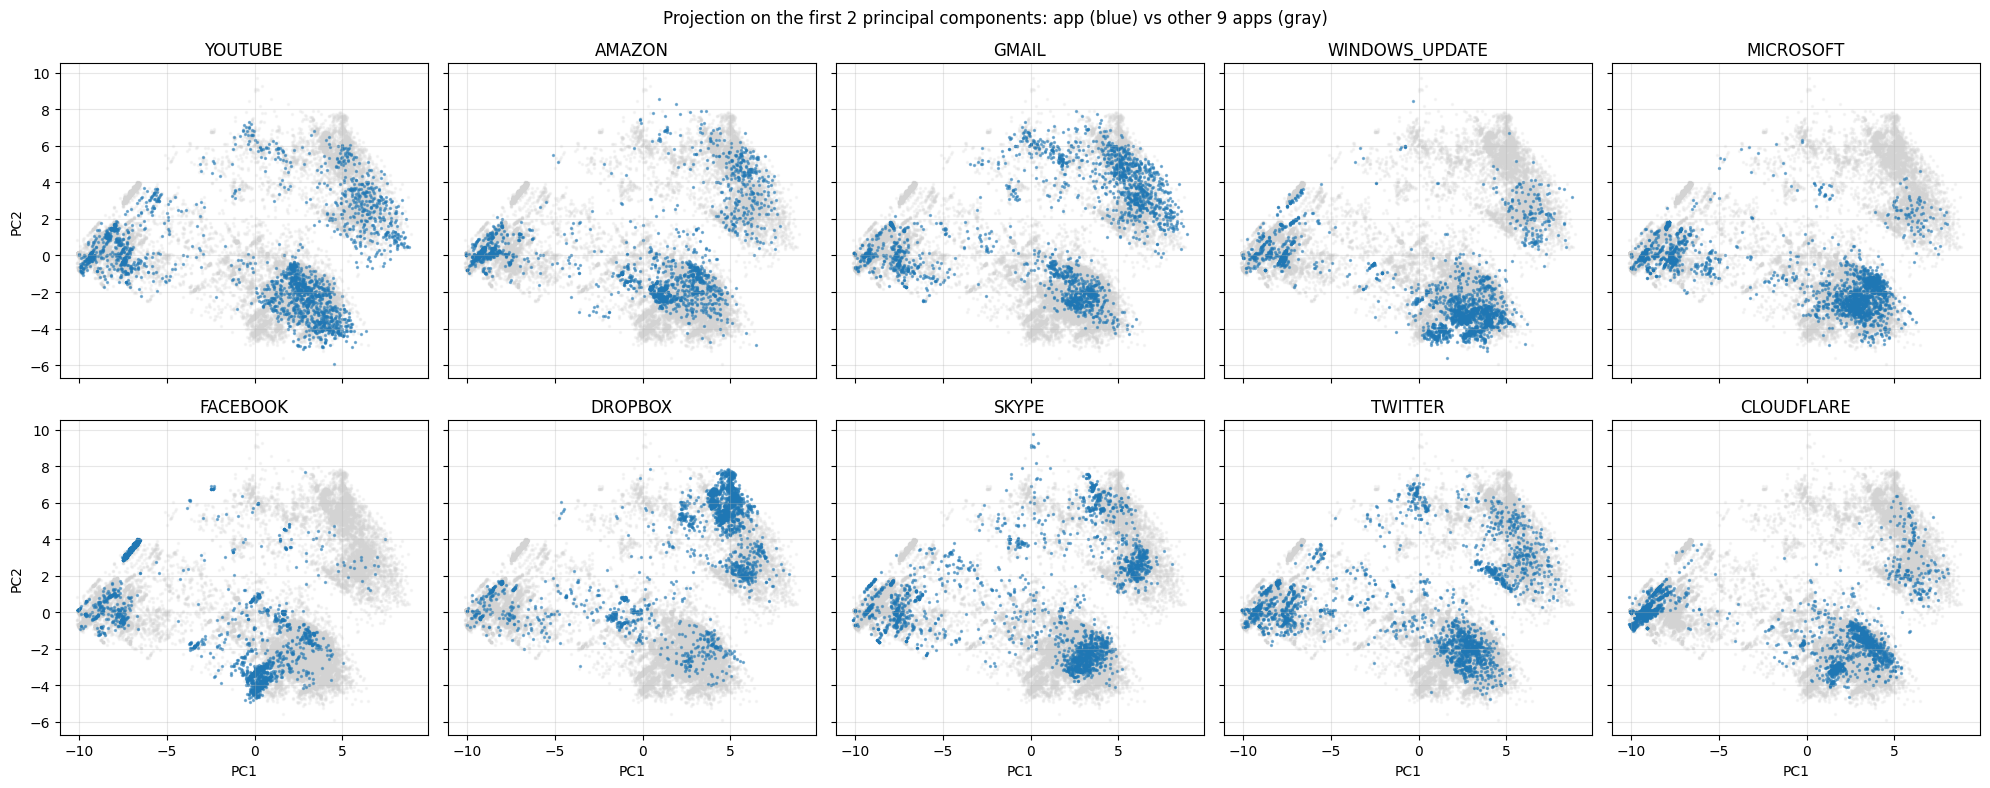

In [32]:
pcs = pd.DataFrame(pca_10.transform(X_std)[:, :2], columns=["PC1", "PC2"], index=X_train_scaled.index)
fig = plot_one_vs_rest(pcs.loc[sample_X.index], sample_y, "PC1", "PC2", "Projection on the first 2 principal components",
                       log=False)
fig.savefig(PLOTS_DIR / "eda_pca_projection.png", dpi=150, bbox_inches="tight")
plt.show()

Comments:
- This confirms the redundancy: 8 components explain 80% of the variance of the 67 features, 14 explain 90%, and 11 have
  eigenvalue > 1.
- PC1 (~43% of the variance) is basically the "size" of the flow: it has the same sign on packet sizes, byte and packet
  counts and durations. PC2 (11.8%) is about active/idle periods (`Idle.*`, `Active.*`) and PC3 (7.2%) about the packet
  rate and the balance between the two directions (`Bwd.Packets.s`, `Down.Up.Ratio`, `Flow.IAT.Mean`).
- The app-specific features only appear from PC4 on, in components with 3.5-5% of the variance each: PC4 opposes the
  proxy port 3128 to ports 443/80 together with the min packet and segment sizes, PC5 mixes the other ports with the min
  backward length and the PSH flags, PC6 opposes the missing server window to its value.
- In the projection we see three clouds: very small flows (left, few packets without payload), normal flows (bottom
  right) and flows with idle periods (top right). Every app is in all three clouds, just in different proportions
  (DROPBOX mostly in the idle one, WINDOWS_UPDATE and MICROSOFT in the normal one). So the directions of max variance
  describe the type of flow and not the app: the app-specific information (ports, window values, specific sizes) has
  little variance and gets lost in a 2D linear projection.
- For this reason we don't use PCA to reduce the inputs of the classifiers: it wouldn't help the trees, and in Section 3
  we need to perturb interpretable features to check if the attacks are realistic.

### Consequences for the models

From the correlation analysis we found three features that are copies of others: `Avg.Fwd.Segment.Size`,
`Avg.Bwd.Segment.Size` and `Packet.Length.Variance`. They don't add information, and in Section 3 an attack that changes
one copy but not the other would create impossible flows, so we remove them.

We keep the correlated features instead: correlated doesn't mean identical (e.g. `Flow.Packets.s` and `Flow.IAT.Mean`
are different on the extreme values) and the redundancy is not a problem for trees and MLP.

The list is in `REDUNDANT_FEATURES` (`src/data.py`). `model_ready.csv` still has them, but `load_model_ready` drops
them when it loads the file, so all the next notebooks use the same 64 features. Here we drop them after the scaling:
since log1p and Min-Max work on each column separately, it's the same as dropping them before.

In [33]:
X_train_model = X_train_scaled.drop(columns=REDUNDANT_FEATURES)
X_test_model = X_test_scaled.drop(columns=REDUNDANT_FEATURES)
print(f"Features: {X_train_scaled.shape[1]} -> {X_train_model.shape[1]}")

Features: 67 -> 64


### Summary

- The features have long tails, many zeros and a lot of redundancy (54 continuous features in 27 groups of correlated
  features, 90% of the variance in 14 PCs). log1p + Min-Max works well: it removes the effect of the tails without
  throwing away the big flows, which are real traffic. We drop the 3 exact copies (the two segment sizes and the
  variance), so we have 64 features; the other correlated features are kept.
- The most useful features for the classification are:
  - the destination port: port 80 for AMAZON and CLOUDFLARE (partly because of how nDPI labels them), the inverted flows
    of DROPBOX, the proxy for WINDOWS_UPDATE;
  - the initial TCP windows `Init_Win_bytes_*`, whose specific values depend on the endpoints (or the proxy) and
    characterize the apps;
  - the packet sizes, in particular max and mean length in each direction;
  - timing: idle periods and max IATs (DROPBOX), throughput (WINDOWS_UPDATE), missing answers from the server
    (FACEBOOK).
- Apart from CLOUDFLARE, AMAZON and DROPBOX, no single feature separates an app from the rest and the apps overlap in the
  2D projections, so the classifiers in Section 2 need many features and non-linear boundaries. Since class 1 is always
  the minority (3-34%), we will compare the models with F1, recall, ROC-AUC and PR-AUC (more sensitive to false positives
  when the positives are only 3%) instead of accuracy. About 2.2% of the flows have the same features as a flow of
  another app, so some error can't be avoided.
- For the attacks (Sections 3-4), the important features are not all equally controllable: the destination port, the
  protocol and the server window can't be changed by the client, while the size of its own packets (padding), the IATs
  (delays) and its own initial window can, but only in some directions. Also, correlated features (e.g. `Flow.Packets.s`
  and `Flow.IAT.Mean`) should be changed together, otherwise the flows are not consistent.

## References

[1] J. S. Rojas, IP Network Traffic Flows Labeled with 75 Apps, Kaggle.
https://www.kaggle.com/datasets/jsrojas/ip-network-traffic-flows-labeled-with-87-apps

[2] G. Draper-Gil, A. H. Lashkari, M. S. I. Mamun, A. A. Ghorbani, "Characterization of Encrypted and VPN Traffic Using
Time-Related Features", ICISSP 2016 (CICFlowMeter).

[3] scikit-learn documentation, https://scikit-learn.org/stable/ (`StratifiedGroupKFold`, `mutual_info_classif`).

[4] RFC 7323, TCP Extensions for High Performance (window scale option).